# Exploración general de datos (EDA)

## 1. Importación de librerías y datos

Primero se realiza un proce de carga homologación de vriables y cruce con municipos para tener la base completa y poder hacer el análisis exploratorio:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from itertools import combinations
import numpy as np

In [ ]:
from cruce_elic import preparar_elic, resumen_elic

# Ruta del archivo completo
archivo = "anex-ELIC-SerieTipoBaseMun-ago2026.xlsx"

# 1. Base de datos ELIC
df_elic = pd.read_excel(
    archivo,
    sheet_name="elic",
    dtype={
        "cod_depto": "string",
        "cod_muni": "string"
    }
)

# 2. Diccionario de códigos
df_guia = pd.read_excel(
    archivo,
    sheet_name="guía",
    header=None
)

# 3. Catálogo de municipios
df_municipios = pd.read_excel(
    archivo,
    sheet_name="lista municipios",
    dtype={
        "cod_depto": "string",
        "cod_muni": "string",
        "cobertura": "string"
    }
)

# Verificar las dimensiones
print("ELIC:", df_elic.shape)
print("Guía:", df_guia.shape)
print("Municipios:", df_municipios.shape)

ELIC: (343545, 15)
Guía: (95, 3)
Municipios: (1104, 5)


In [2]:
df_codigos, df_analisis, auditoria = preparar_elic(
    df_elic,
    df_guia,
    df_municipios
)

print("Registros originales:", len(df_elic))
print("Registros finales:", len(df_analisis))

print(
    "Municipios sin cruce:",
    (~df_codigos["municipio_encontrado"]).sum()
)

print("Códigos sin homologar:", len(auditoria))

display(df_analisis.head())
display(auditoria)

Registros originales: 343545
Registros finales: 343545
Municipios sin cruce: 0
Códigos sin homologar: 0


,ano,mes,cod_depto,cod_muni,obj_tra,clase_suelo,modalidad,destino,tipo_vivi,vis_novis,...,fecha,cobertura_coincide,obj_tra_codigo,clase_suelo_codigo,modalidad_codigo,destino_codigo,tipo_vivi_codigo,vis_novis_codigo,estrato_codigo,cobertura_codigo
0,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,2005-01-01,True,1,1,1,1,1,2,2,77
1,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,2005-01-01,True,1,1,1,1,1,2,3,77
2,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,2005-01-01,True,1,1,1,1,1,2,5,77
3,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,2005-01-01,True,1,1,1,1,2,1,2,77
4,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,2005-01-01,True,1,1,1,1,2,1,3,77


,variable,codigo,registros


Dado que no sabemos si más adelante se necesiten los códigos para cruzarlos con otras bases el análisis exploratorio se realizará sobre una copia.

In [ ]:
# Crear una copia para el análisis exploratorio
df = df_analisis.copy()

# Eliminar columnas auxiliares de códigos
columnas_codigos = [
    col for col in df.columns
    if col.endswith("_codigo")
]

df = df.drop(columns=columnas_codigos)

,ano,mes,cod_depto,cod_muni,obj_tra,clase_suelo,modalidad,destino,tipo_vivi,vis_novis,...,unidades,licencias,cobertura,departamento,municipio,cobertura_municipio,municipio_encontrado,divipola,fecha,cobertura_coincide
0,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,2,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
1,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,1,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
2,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,1,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
3,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,73,5,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
4,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,7,2,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343545 entries, 0 to 343544
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   ano                   343545 non-null  int64         
 1   mes                   343545 non-null  int64         
 2   cod_depto             343545 non-null  string        
 3   cod_muni              343545 non-null  string        
 4   obj_tra               343545 non-null  string        
 5   clase_suelo           343545 non-null  string        
 6   modalidad             343545 non-null  string        
 7   destino               343545 non-null  string        
 8   tipo_vivi             343545 non-null  string        
 9   vis_novis             343545 non-null  string        
 10  estrato               343545 non-null  string        
 11  area                  343545 non-null  int64         
 12  unidades              343545 non-null  int64         
 13 

## 2. Conocimiento inicial de la base

Revisamos tamaño, columnas y tipos de datos para comprender qué representa cada registro y qué variables están disponibles.

In [7]:
# Número de filas y columnas
print("Filas y columnas:", df.shape)

# Primeras observaciones
df.head()

Filas y columnas: (343545, 22)


,ano,mes,cod_depto,cod_muni,obj_tra,clase_suelo,modalidad,destino,tipo_vivi,vis_novis,...,unidades,licencias,cobertura,departamento,municipio,cobertura_municipio,municipio_encontrado,divipola,fecha,cobertura_coincide
0,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,2,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
1,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,1,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
2,2005,1,05,001,nuevo,urbana,nueva,vivienda,casas,No VIS,...,1,1,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
3,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,73,5,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True
4,2005,1,05,001,nuevo,urbana,nueva,vivienda,apartamentos,"VIS (sin desagregación VIP, antes de 2013)",...,7,2,Pertenece a la cobertura de 77 municipios,Antioquia,Medellín,77,True,05001,2005-01-01,True


Granularidad:
Cada fila corresponde a un registro agregado mensual  de licencias de construcción para un municipio, desagregado según según características del trámite, clase de suelo, modalidad, destino, tipo de vivienda, clasificación VIS/No VIS y estrato socioeconómico.
Cada fila contiene indicadores de área aprobada, unidades de vivienda y número de licencias.

In [8]:
# Tipos de datos y cantidad de registros no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343545 entries, 0 to 343544
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   ano                   343545 non-null  int64         
 1   mes                   343545 non-null  int64         
 2   cod_depto             343545 non-null  string        
 3   cod_muni              343545 non-null  string        
 4   obj_tra               343545 non-null  string        
 5   clase_suelo           343545 non-null  string        
 6   modalidad             343545 non-null  string        
 7   destino               343545 non-null  string        
 8   tipo_vivi             343545 non-null  string        
 9   vis_novis             343545 non-null  string        
 10  estrato               343545 non-null  string        
 11  area                  343545 non-null  int64         
 12  unidades              343545 non-null  int64         
 13 

## 3. Evaluación de la calidad de los datos

### 3.1. Completitud

La completitud indica cuánto dato está disponible en cada variable. Calculamos los valores nulos y sus porcentajes sin modificar la base.

In [9]:
completitud = pd.DataFrame({
    "Valores nulos": df.isna().sum(),
    "% Nulos": (df.isna().sum() / len(df) * 100).round(2),
    "% Completitud": (100 - df.isna().sum() / len(df) * 100).round(2)
})

completitud.sort_values("% Completitud")

,Valores nulos,% Nulos,% Completitud
ano,0,0.0,100.0
divipola,0,0.0,100.0
municipio_encontrado,0,0.0,100.0
cobertura_municipio,0,0.0,100.0
municipio,0,0.0,100.0
departamento,0,0.0,100.0
cobertura,0,0.0,100.0
licencias,0,0.0,100.0
unidades,0,0.0,100.0
area,0,0.0,100.0


Vemos que ninguno de los 343.545 registros tiene datos nulos incluso después de haber hecho el cruce de los datos. 

### 3.2. Consistencia

In [11]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


Vemos que la base tampoco tiene registro duplicados.

### 3.3. Claridad

In [12]:
claridad = pd.DataFrame({
    "Tipo de dato": df.dtypes,
    "Valores únicos": df.nunique()
})

claridad

,Tipo de dato,Valores únicos
ano,int64,22
mes,int64,12
cod_depto,string[python],33
cod_muni,string[python],571
obj_tra,string[python],2
clase_suelo,string[python],3
modalidad,string[python],2
destino,string[python],12
tipo_vivi,string[python],3
vis_novis,string[python],5


In [16]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, df[col].dropna().unique()[:15]))
        for col in df.columns
    ],
    "Total valores únicos": [
        df[col].nunique()
        for col in df.columns
    ]
})

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,ano,int64,"2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012...",22
1,mes,int64,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",12
2,cod_depto,string,"05, 08, 11, 13, 15, 17, 18, 19, 20, 23, 25, 27...",33
3,cod_muni,string,"001, 079, 088, 129, 212, 266, 308, 360, 380, 6...",571
4,obj_tra,string,"nuevo, modificación",2
5,clase_suelo,string,"urbana, rural, sub-urbana",3
6,modalidad,string,"nueva, ampliación",2
7,destino,string,"vivienda, oficina, comercio, otros, industria,...",12
8,tipo_vivi,string,"casas, apartamentos, No aplica",3
9,vis_novis,string,"No VIS, VIS (sin desagregación VIP, antes de 2...",5


De acuerdo con la muestra de cada columna se observa que los campos principales tienen correctamente definido el tipo de dato.

## 4. Descripción estadística de variables numéricas

Resumen de media, desviación estándar, mínimos, máximos y cuartiles.

In [19]:
numericas = df.select_dtypes(include="number").drop(columns=["ano","mes"])

if numericas.shape[1] > 0:
    display(numericas.describe().style.format("{:,.0f}"))
else:
    print("Esta base no tiene columnas numéricas reconocidas por pandas.")

,area,unidades,licencias
count,"343,545","343,545","343,545"
mean,"1,408",12,2
std,"6,320",75,4
min,1,0,0
25%,123,0,1
50%,265,1,1
75%,653,4,2
max,"577,481","6,180",302


Vemos que los tres campos numéricos comparten su concentración de datos en los valores bajoso y tienen una cola larga hacía los valores altos, procedemos a ver la distribución en la gráfica:

## 5. Exploración gráfica de variables numéricas

Primero se revisan los histogramas; luego, los diagramas de caja. Ambos procedimientos aparecen en los talleres.

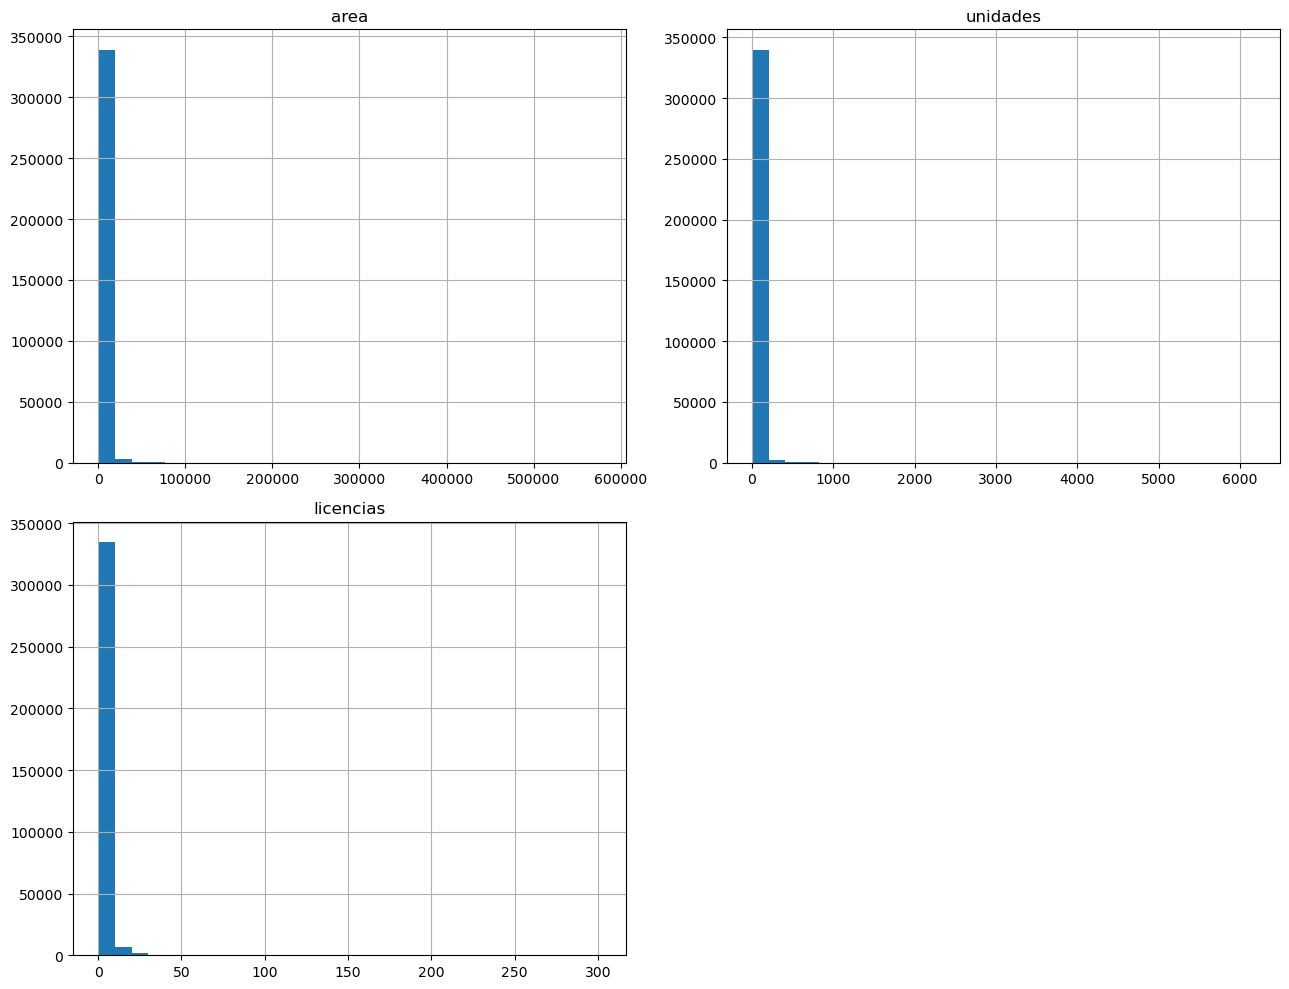

In [20]:
# Histogramas de las columnas numéricas
if numericas.shape[1] > 0:
    numericas.hist(figsize=(13, 10), bins=30)
    plt.tight_layout()
    plt.show()

Efectivamente los gráficos nos muestran una fuerte asimetria positiva y la presencia de valores extremos, vamos a realizar un zoom in esta información:

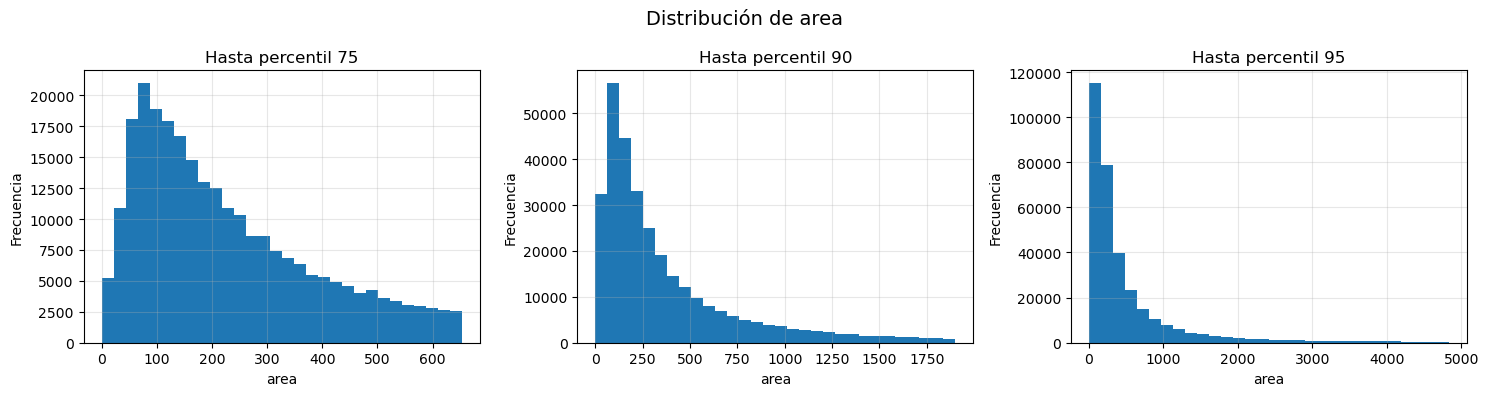

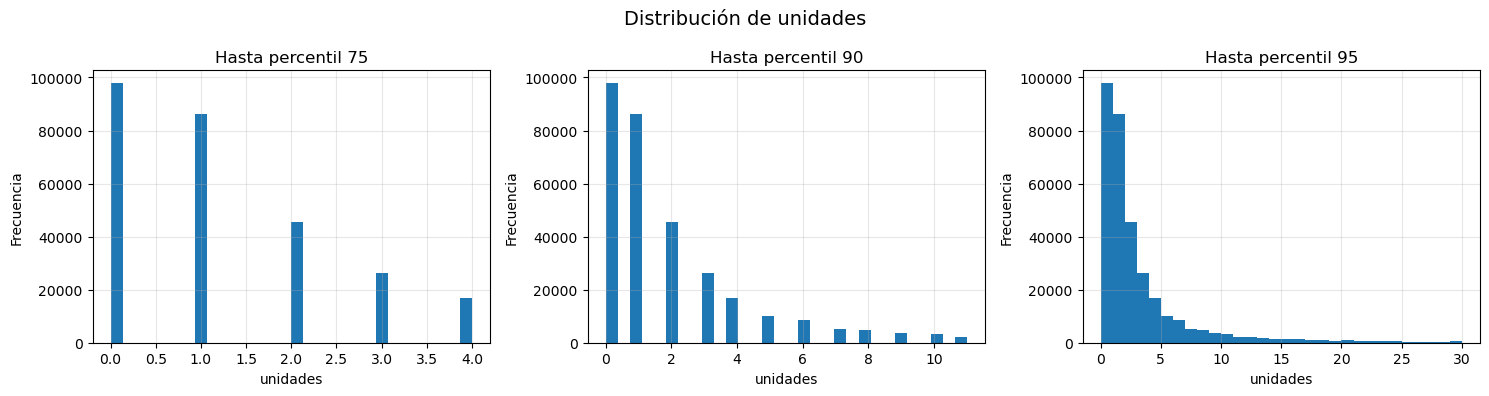

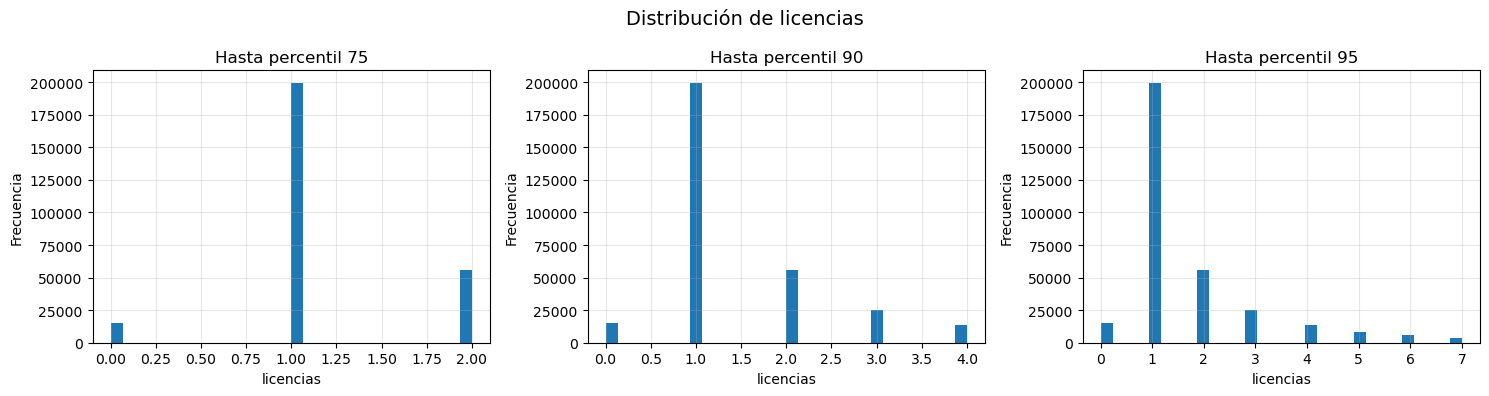

In [25]:
percentiles = [0.75, 0.90, 0.95]

for col in numericas.columns:

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, p in zip(axes, percentiles):

        limite = numericas[col].quantile(p)

        ax.hist(
            numericas[col].dropna(),
            bins=30,
            range=(0, limite)
        )

        ax.set_title(f"Hasta percentil {p*100:.0f}")
        ax.set_xlabel(col)
        ax.set_ylabel("Frecuencia")
        ax.grid(alpha=0.3)

    fig.suptitle(f"Distribución de {col}", fontsize=14)
    plt.tight_layout()
    plt.show()

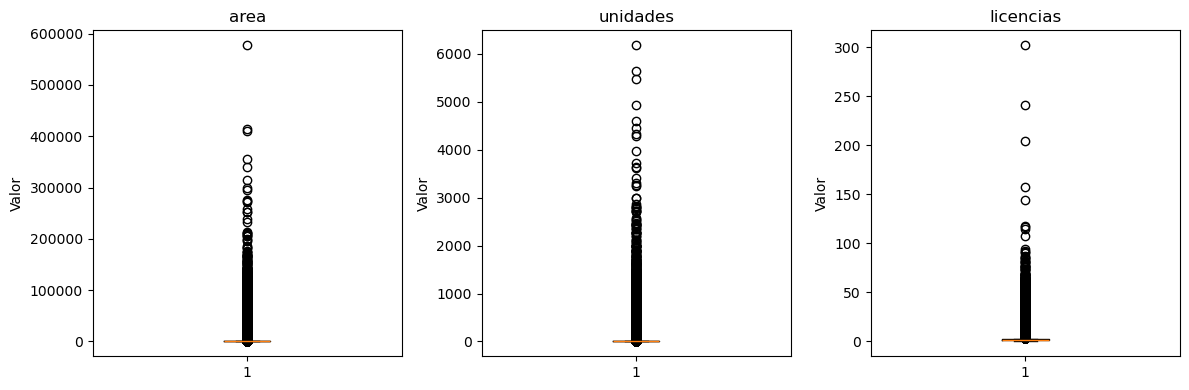

In [23]:
# Diagramas de caja por variable numérica
if numericas.shape[1] > 0:
    columnas = 3
    filas = math.ceil(numericas.shape[1] / columnas)

    plt.figure(figsize=(12, 4 * filas))

    for i, col in enumerate(numericas.columns):
        plt.subplot(filas, columnas, i + 1)
        plt.boxplot(numericas[col].dropna())
        plt.title(col)
        plt.ylabel("Valor")

    plt.tight_layout()
    plt.show()

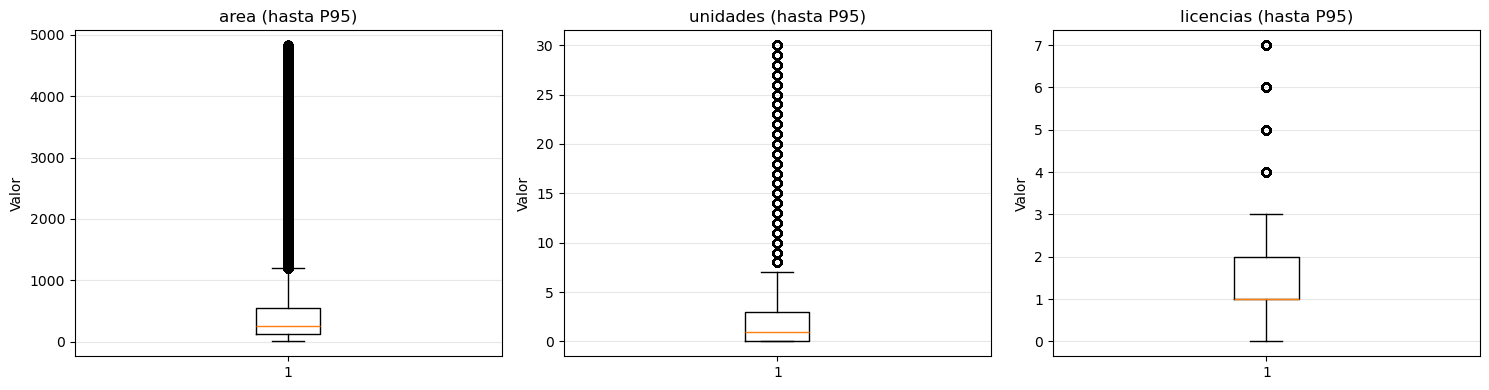

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numericas.columns):

    limite = numericas[col].quantile(0.95)

    datos = numericas[col].dropna()
    datos = datos[datos <= limite]

    axes[i].boxplot(datos)
    axes[i].set_title(f"{col} (hasta P95)")
    axes[i].set_ylabel("Valor")
    axes[i].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Identificación de posibles outliers:

In [27]:
resumen_outliers = []

for col in numericas.columns:

    q1 = numericas[col].quantile(0.25)
    q3 = numericas[col].quantile(0.75)

    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr

    cantidad = (numericas[col] > limite_superior).sum()

    resumen_outliers.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "Límite superior": limite_superior,
        "Cantidad posibles outliers": cantidad,
        "% posibles outliers": cantidad / numericas[col].notna().sum() * 100
    })

display(pd.DataFrame(resumen_outliers).round(2))

,Variable,Q1,Q3,Límite superior,Cantidad posibles outliers,% posibles outliers
0,area,123.0,653.0,1448.0,43068,12.54
1,unidades,0.0,4.0,10.0,35548,10.35
2,licencias,1.0,2.0,3.5,47808,13.92


Inicialmente se podría pensar que estos valores altos en área pertenecen a proyectos distintos de vivienda, tales como comercio o industria por lo cuál se procede a hacer la comprobación.

In [ ]:
# Calcular el límite superior mediante IQR
q1 = df["area"].quantile(0.25)
q3 = df["area"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

# Identificar posibles valores atípicos
outliers = df[df["area"] > limite_superior].copy()

In [ ]:
# Revisar a qué categorías pertenecen
display(outliers["destino"].value_counts(dropna=False).to_frame("Cantidad de registros"))

,Cantidad de registros
destino,
vivienda,29396
comercio,4248
educación,2155
bodega,1801
industria,1541
alojamiento,980
salud-asistencial,942
oficina,793
social-recreacional,542


PENDIENTE VER SI ES PORQUE IGUAL EN VIVIENDA HAY MÁS REGISTROS

## 6. Exploración de variables categóricas

In [51]:
categoricas = df.select_dtypes(include=["object", "category", "bool", "string"]).drop(columns=["cod_depto","cod_muni","municipio_encontrado","divipola","cobertura_coincide"])

In [52]:
categoricas.columns

Index(['obj_tra', 'clase_suelo', 'modalidad', 'destino', 'tipo_vivi',
       'vis_novis', 'estrato', 'cobertura', 'departamento', 'municipio',
       'cobertura_municipio'],
      dtype='object')

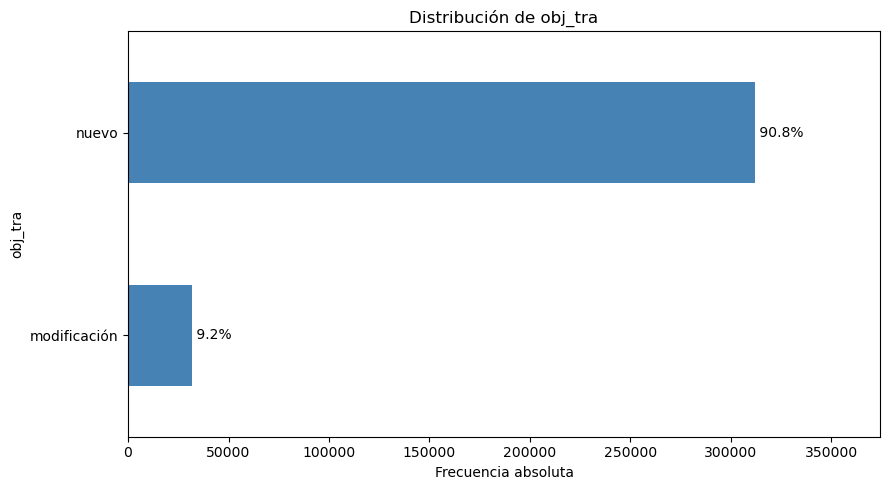

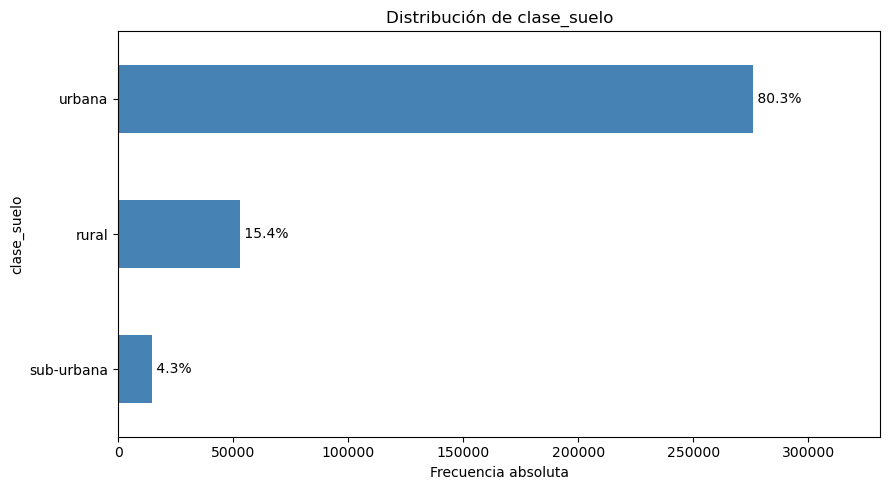

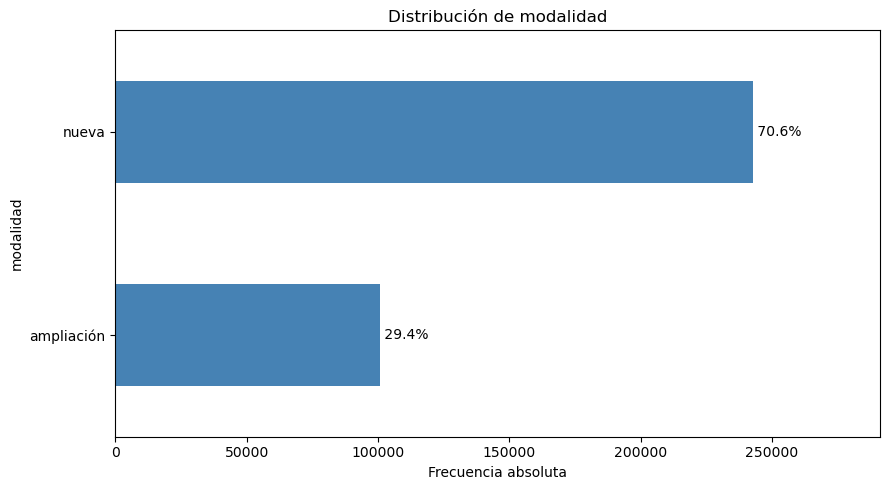

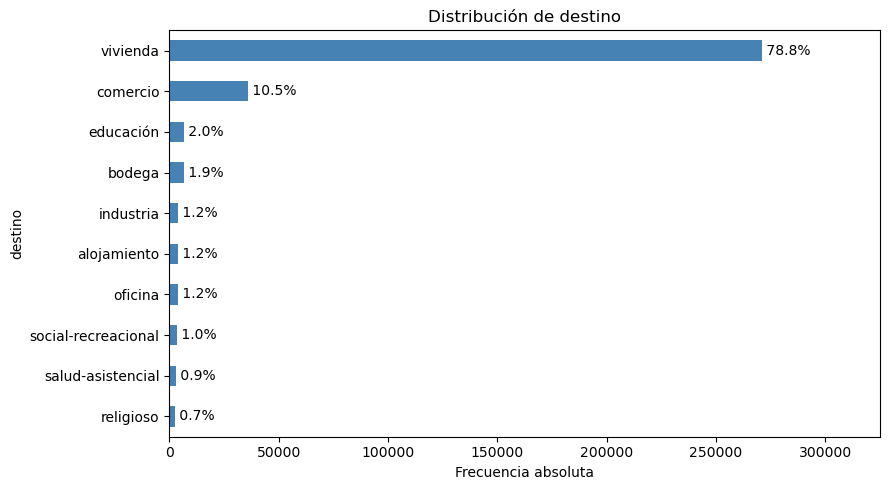

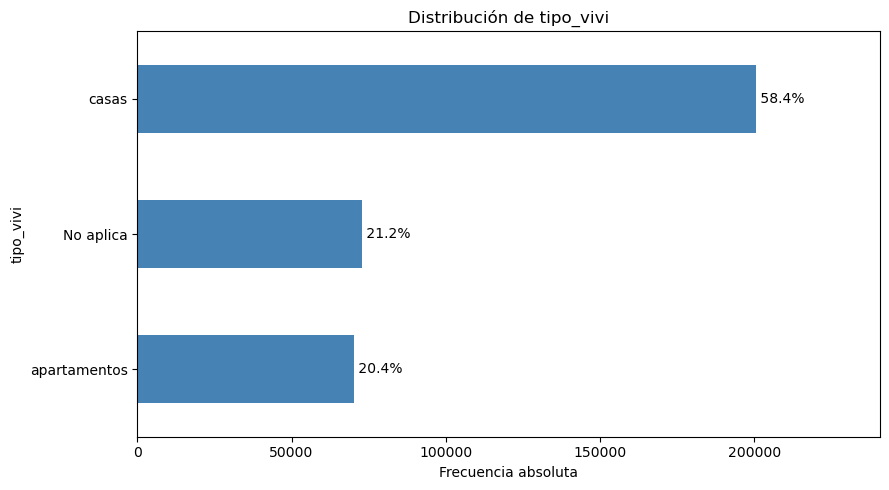

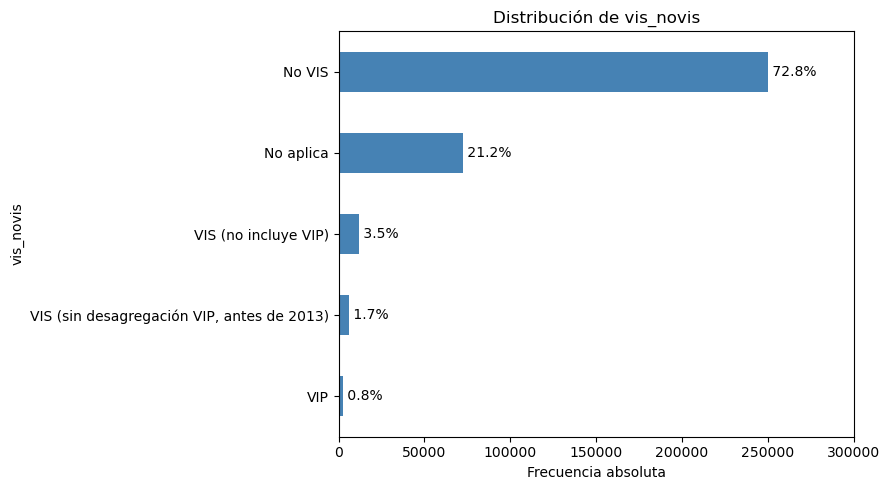

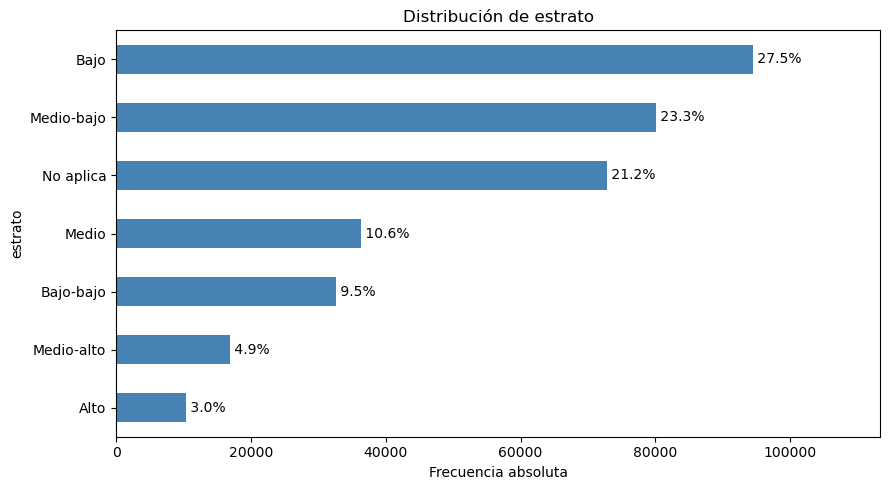

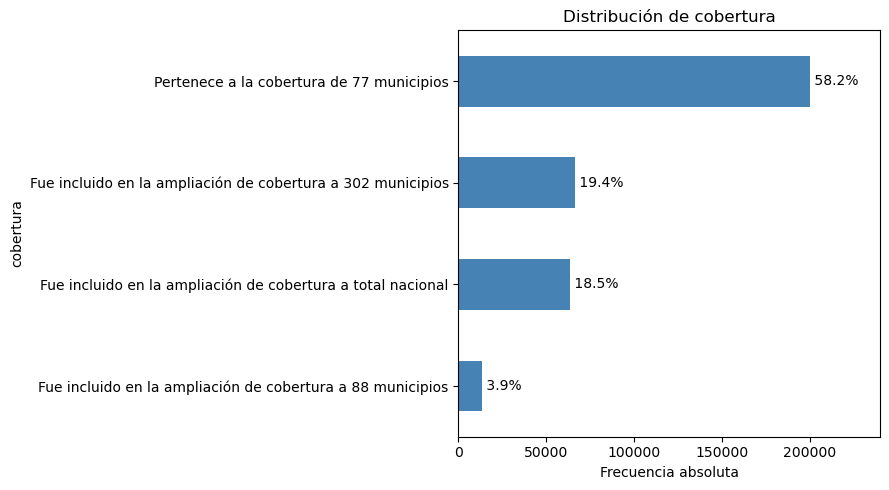

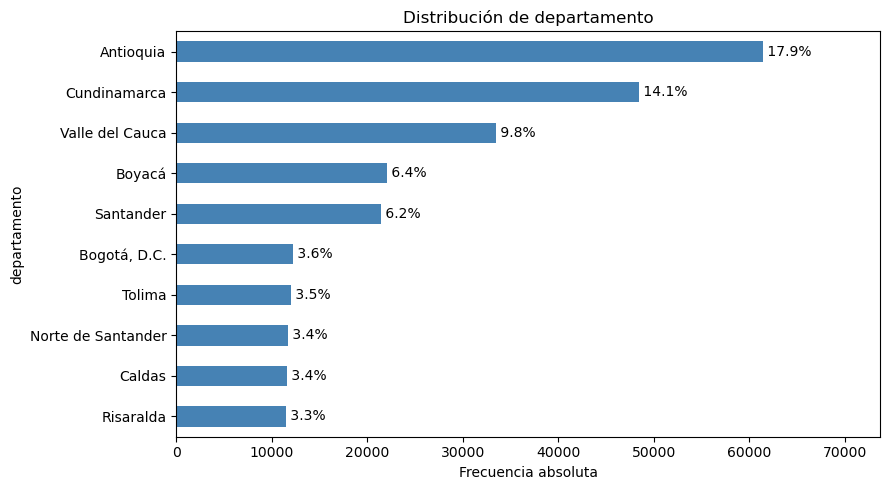

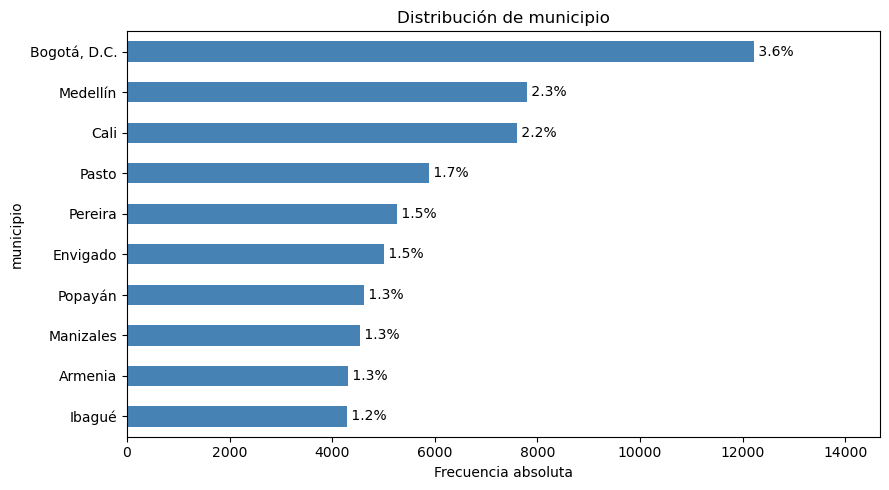

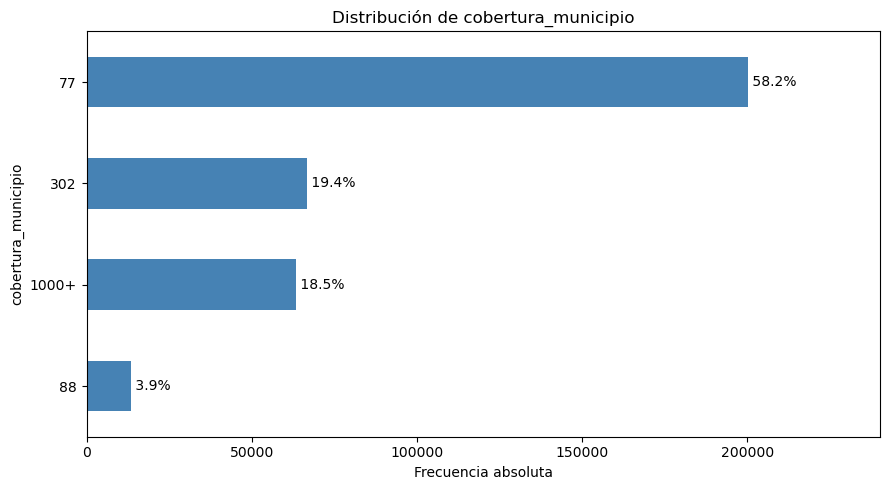

In [55]:
for col in categoricas.columns:

    frecuencias = df[col].value_counts(
        dropna=False
    ).head(10).sort_values()

    ax = frecuencias.plot(
        kind="barh",
        figsize=(9, 5),
        color="steelblue"
    )

    # Agregar porcentajes al final de cada barra
    for i, valor in enumerate(frecuencias):
        porcentaje = (valor / len(df)) * 100
        ax.text(valor, i, f" {porcentaje:.1f}%", va="center")

    plt.title(f"Distribución de {col}")
    plt.xlabel("Frecuencia absoluta")
    plt.ylabel(col)
    plt.xlim(0, frecuencias.max() * 1.20)
    plt.tight_layout()
    plt.show()

In [68]:
print(categoricas2.columns.tolist())

['obj_tra', 'clase_suelo', 'modalidad', 'destino', 'tipo_vivi', 'vis_novis', 'estrato', 'departamento']



Tabla cruzada: obj_tra vs clase_suelo


clase_suelo,rural,sub-urbana,urbana
obj_tra,,,
modificación,8.7,2.25,89.05
nuevo,16.1,4.46,79.43


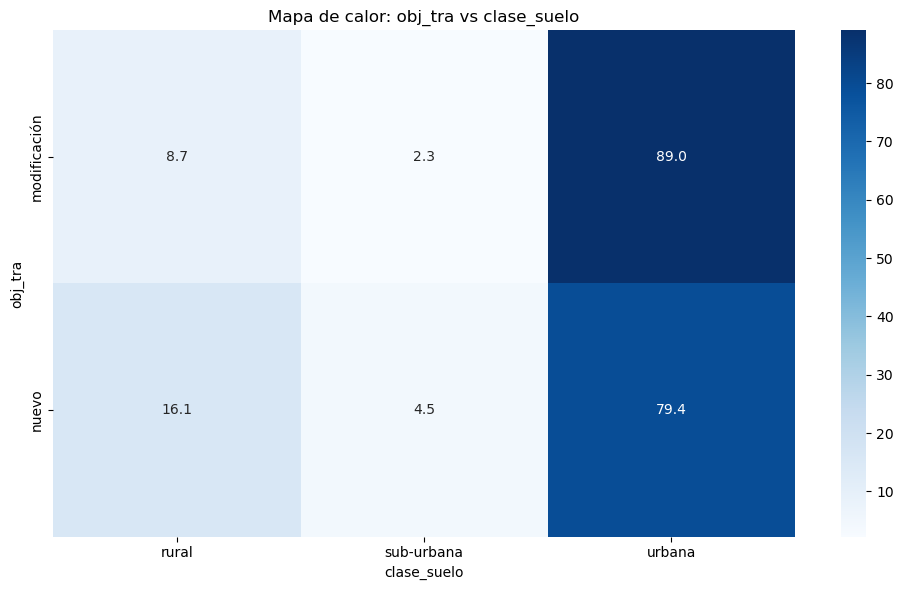


Tabla cruzada: obj_tra vs modalidad


modalidad,ampliación,nueva
obj_tra,,
modificación,92.60,7.40
nuevo,22.95,77.05


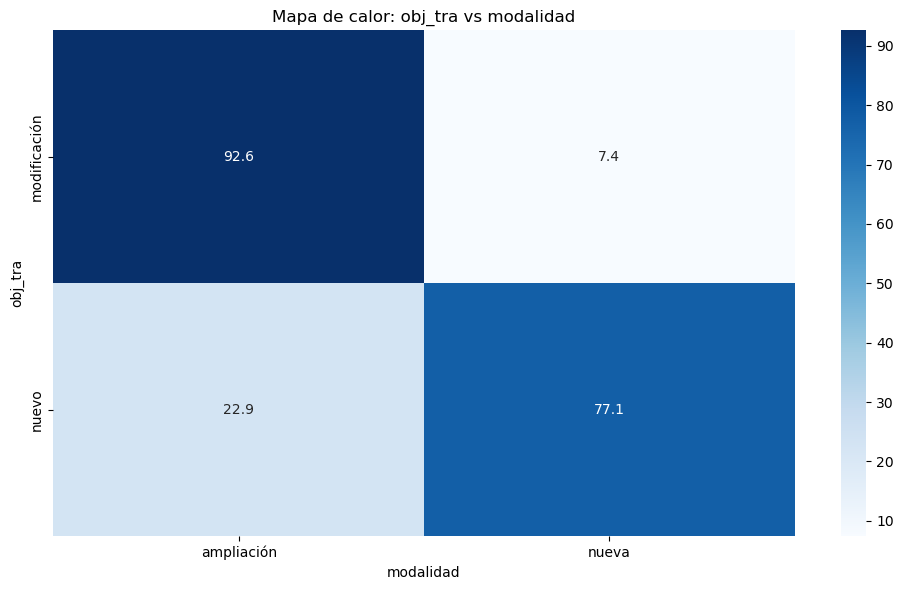


Tabla cruzada: obj_tra vs destino


destino,administración pública,alojamiento,bodega,comercio,educación,industria,oficina,otros,religioso,salud-asistencial,social-recreacional,vivienda
obj_tra,,,,,,,,,,,,
modificación,0.42,1.54,1.37,10.66,2.87,1.51,1.89,0.33,0.71,1.34,0.68,76.68
nuevo,0.41,1.13,2.01,10.43,1.86,1.14,1.07,0.28,0.73,0.89,1.00,79.04


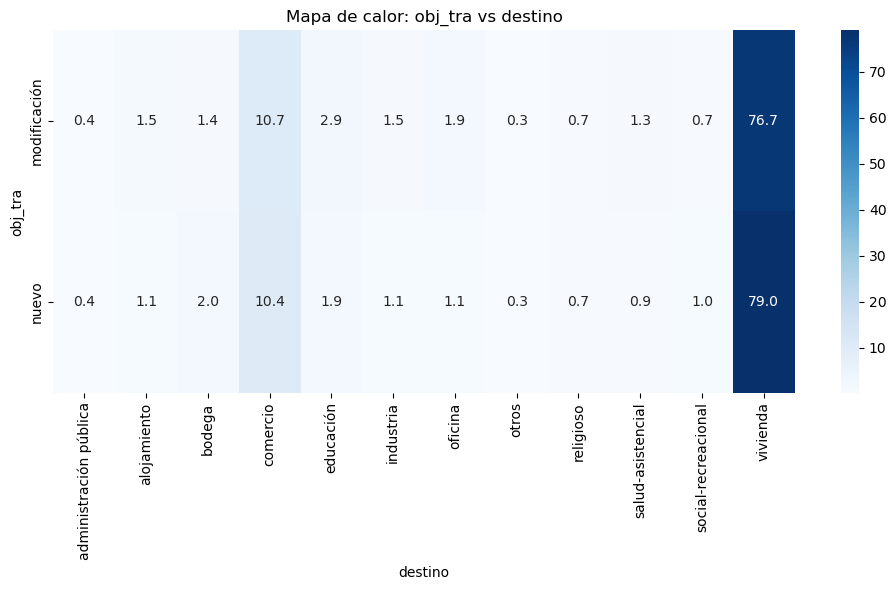


Tabla cruzada: obj_tra vs tipo_vivi


tipo_vivi,No aplica,apartamentos,casas
obj_tra,,,
modificación,23.32,29.23,47.45
nuevo,20.96,19.54,59.50


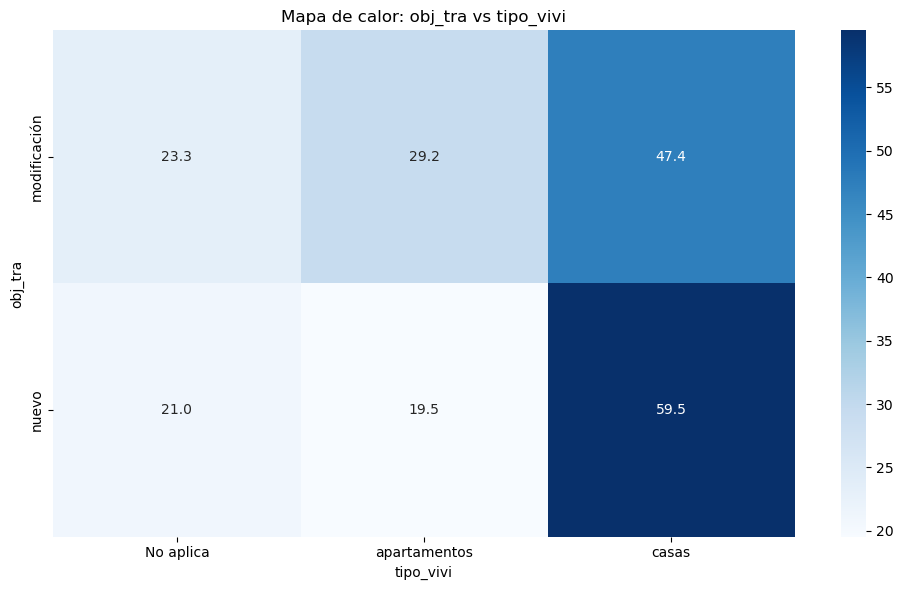


Tabla cruzada: obj_tra vs vis_novis


vis_novis,No VIS,No aplica,VIP,VIS (no incluye VIP),"VIS (sin desagregación VIP, antes de 2013)"
obj_tra,,,,,
modificación,75.53,23.32,0.18,0.81,0.16
nuevo,72.57,20.96,0.84,3.73,1.90


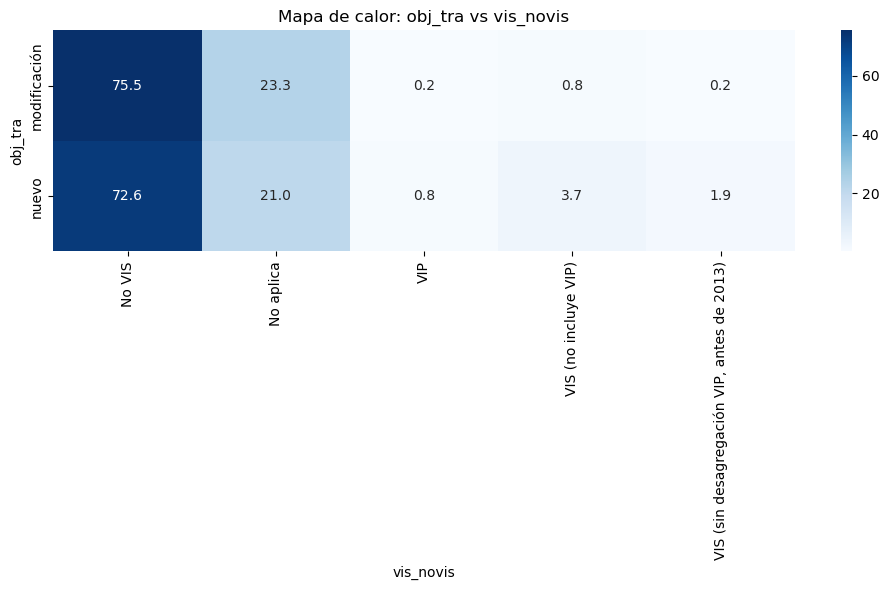


Tabla cruzada: obj_tra vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
obj_tra,,,,,,,
modificación,4.13,23.17,4.84,12.08,5.90,26.56,23.32
nuevo,2.93,27.93,9.97,10.40,4.82,23.00,20.96


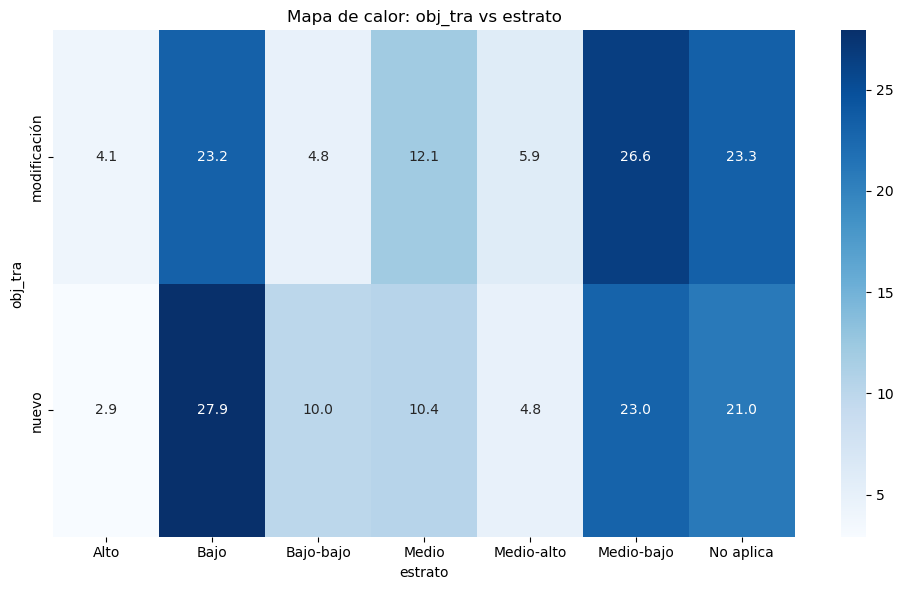


Tabla cruzada: obj_tra vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
obj_tra,,,,,,,,,,,,,,,,,,,,,
modificación,0.04,34.02,0.05,4.83,8.41,2.36,4.80,3.15,0.52,2.19,...,0.08,2.37,1.40,0.04,3.53,1.19,1.95,2.74,0.06,0.02
nuevo,0.12,16.23,0.60,2.82,3.07,1.75,6.59,3.41,0.66,1.20,...,0.63,2.57,3.54,0.11,6.51,1.21,3.65,10.47,0.07,0.08


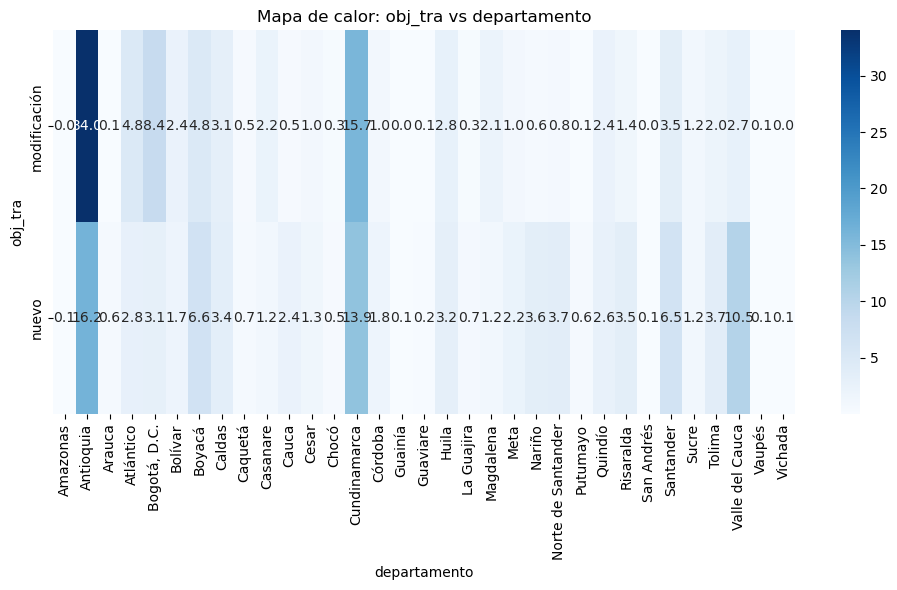


Tabla cruzada: clase_suelo vs modalidad


modalidad,ampliación,nueva
clase_suelo,,
rural,15.58,84.42
sub-urbana,16.54,83.46
urbana,32.70,67.30


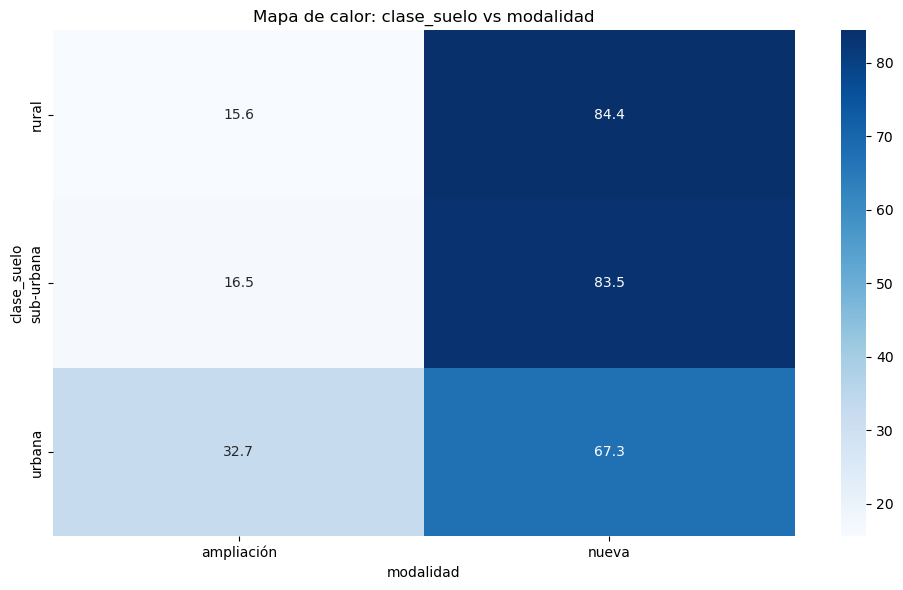


Tabla cruzada: clase_suelo vs destino


destino,administración pública,alojamiento,bodega,comercio,educación,industria,oficina,otros,religioso,salud-asistencial,social-recreacional,vivienda
clase_suelo,,,,,,,,,,,,
rural,0.24,1.54,2.81,5.97,2.73,2.52,0.46,0.58,0.51,0.25,1.64,80.75
sub-urbana,0.28,1.26,4.46,7.43,1.73,3.71,0.65,0.22,0.53,0.41,1.07,78.25
urbana,0.45,1.09,1.65,11.48,1.82,0.78,1.31,0.24,0.77,1.10,0.84,78.48


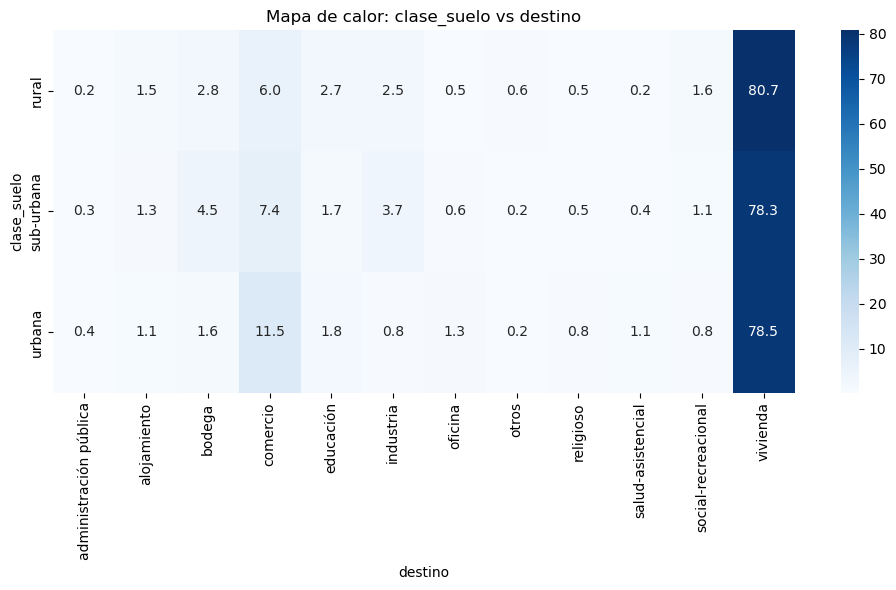


Tabla cruzada: clase_suelo vs tipo_vivi


tipo_vivi,No aplica,apartamentos,casas
clase_suelo,,,
rural,19.25,2.88,77.87
sub-urbana,21.75,6.75,71.50
urbana,21.52,24.53,53.95


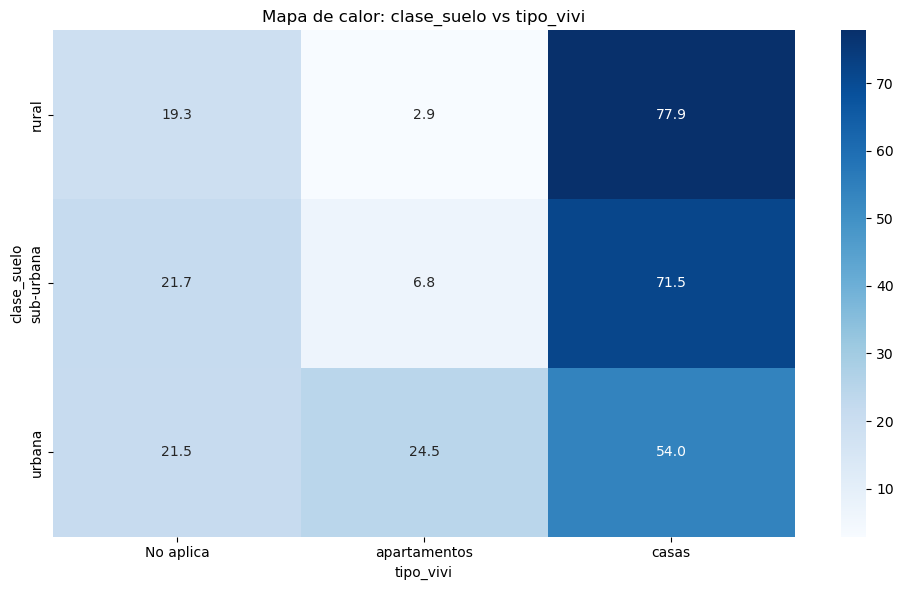


Tabla cruzada: clase_suelo vs vis_novis


vis_novis,No VIS,No aplica,VIP,VIS (no incluye VIP),"VIS (sin desagregación VIP, antes de 2013)"
clase_suelo,,,,,
rural,77.15,19.25,0.72,2.39,0.50
sub-urbana,74.20,21.75,0.61,2.70,0.74
urbana,71.95,21.52,0.80,3.71,2.03


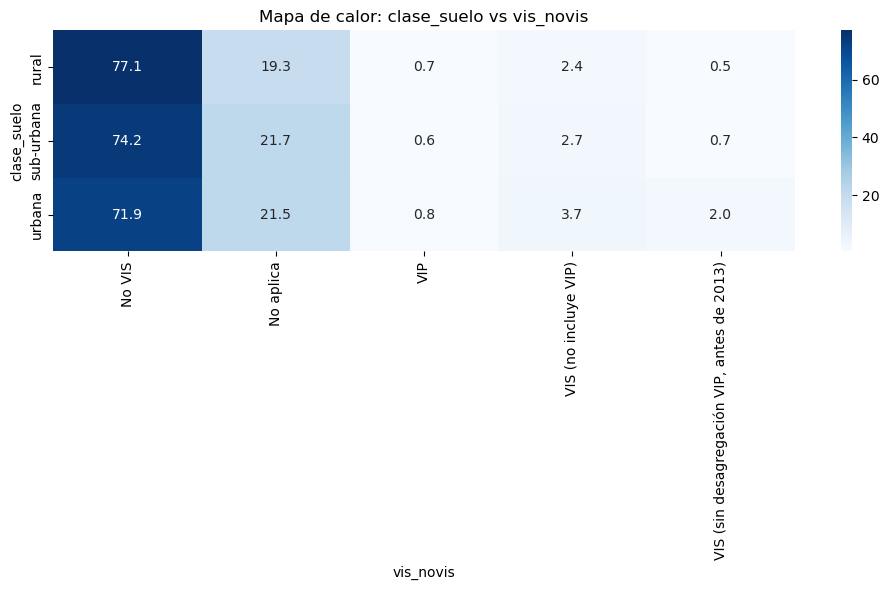


Tabla cruzada: clase_suelo vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
clase_suelo,,,,,,,
rural,5.09,26.34,10.77,12.10,7.67,18.78,19.25
sub-urbana,10.08,20.88,8.55,13.16,10.24,15.34,21.75
urbana,2.27,28.06,9.31,10.12,4.11,24.62,21.52


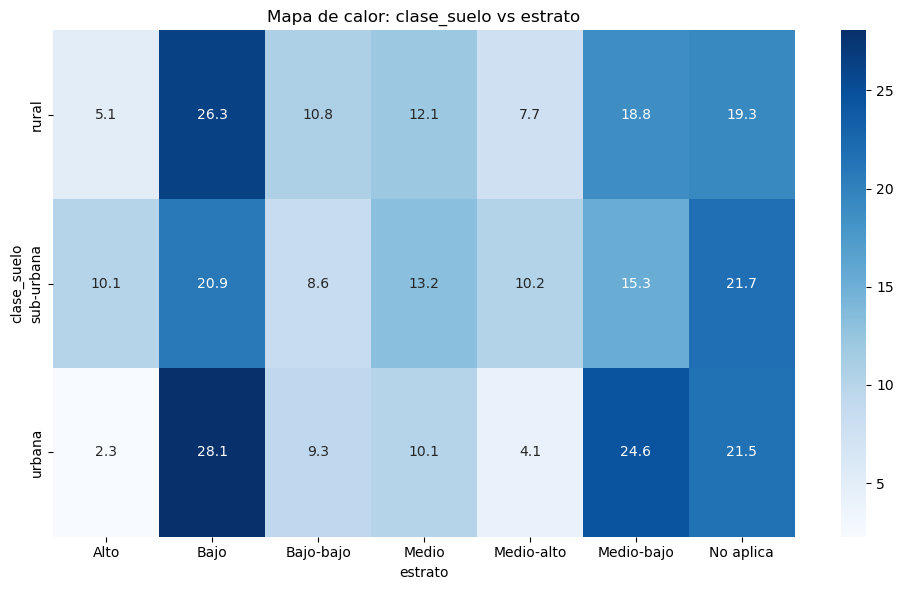


Tabla cruzada: clase_suelo vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
clase_suelo,,,,,,,,,,,,,,,,,,,,,
rural,0.03,24.13,0.20,0.47,0.00,0.56,8.81,2.09,0.33,0.49,...,0.37,2.19,2.18,0.21,4.28,0.28,2.21,7.72,0.00,0.02
sub-urbana,0.05,12.14,0.04,2.07,0.14,2.28,5.08,4.08,0.23,0.63,...,0.40,3.83,7.35,0.07,8.72,0.53,1.21,14.27,0.00,0.00
urbana,0.13,16.98,0.65,3.55,4.42,2.02,6.04,3.60,0.73,1.48,...,0.62,2.56,3.35,0.09,6.48,1.42,3.87,9.91,0.09,0.08


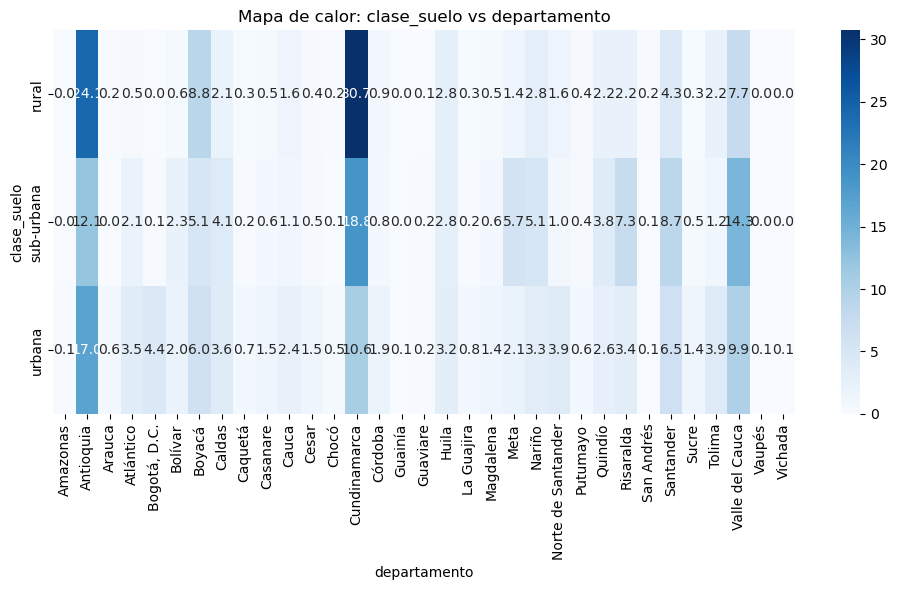


Tabla cruzada: modalidad vs destino


destino,administración pública,alojamiento,bodega,comercio,educación,industria,oficina,otros,religioso,salud-asistencial,social-recreacional,vivienda
modalidad,,,,,,,,,,,,
ampliación,0.41,1.29,1.21,8.68,3.32,1.35,1.38,0.22,0.73,1.39,0.70,79.32
nueva,0.41,1.12,2.26,11.19,1.39,1.10,1.05,0.31,0.72,0.75,1.08,78.61


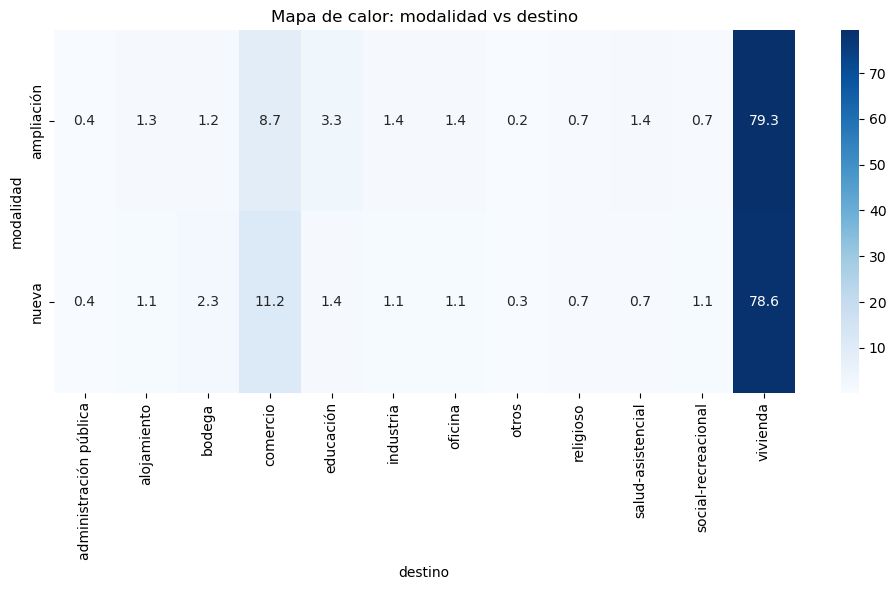


Tabla cruzada: modalidad vs tipo_vivi


tipo_vivi,No aplica,apartamentos,casas
modalidad,,,
ampliación,20.68,26.10,53.22
nueva,21.39,18.08,60.53


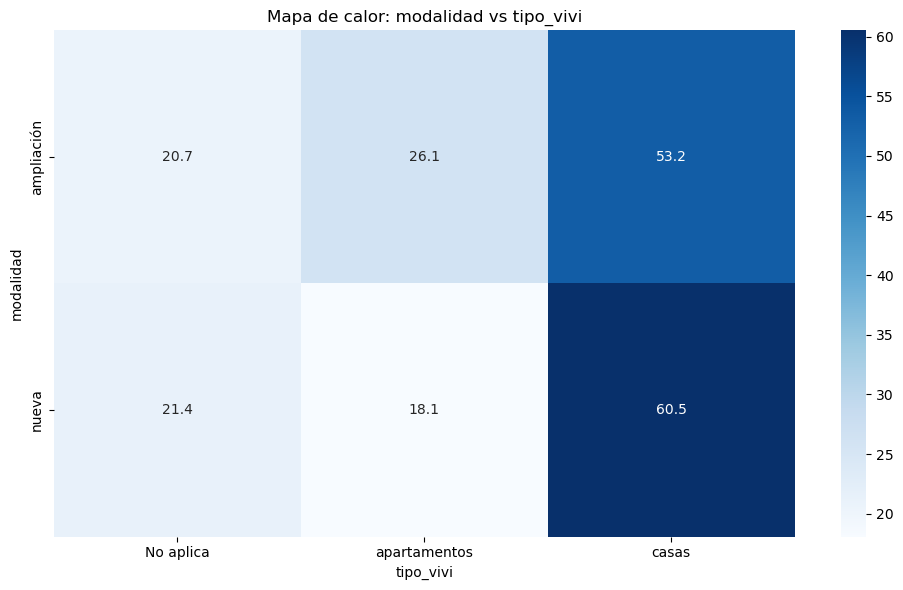


Tabla cruzada: modalidad vs vis_novis


vis_novis,No VIS,No aplica,VIP,VIS (no incluye VIP),"VIS (sin desagregación VIP, antes de 2013)"
modalidad,,,,,
ampliación,79.32,20.68,0.0,0.00,0.00
nueva,70.15,21.39,1.1,4.91,2.46


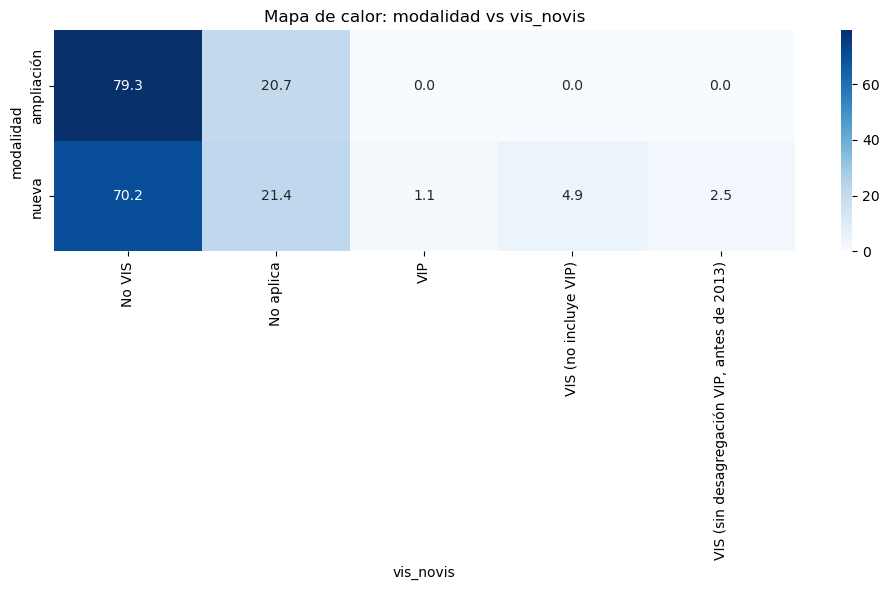


Tabla cruzada: modalidad vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
modalidad,,,,,,,
ampliación,2.84,27.30,7.13,10.71,4.64,26.69,20.68
nueva,3.12,27.56,10.49,10.49,5.04,21.92,21.39


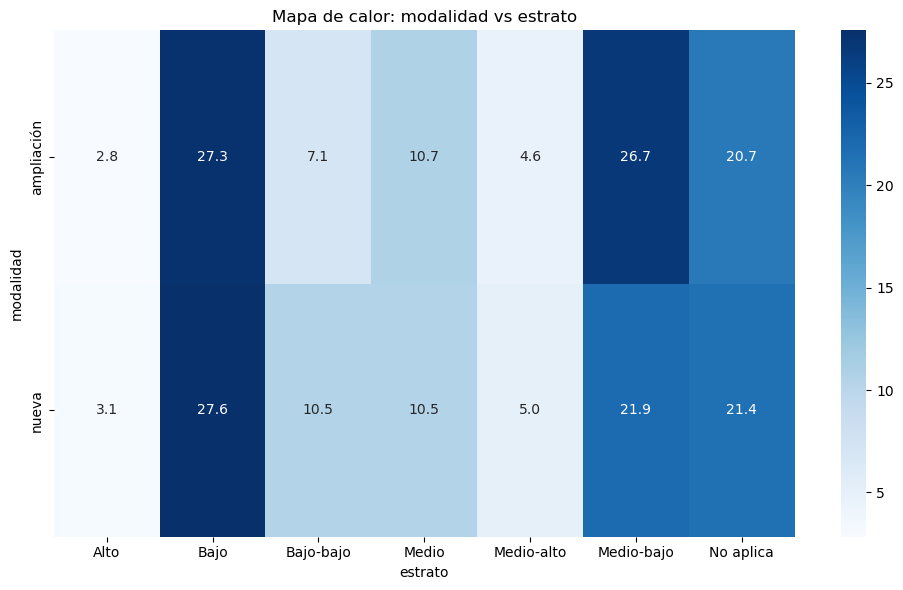


Tabla cruzada: modalidad vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
modalidad,,,,,,,,,,,,,,,,,,,,,
ampliación,0.07,22.58,0.27,3.37,5.63,1.65,5.13,4.12,0.43,1.05,...,0.23,3.67,3.46,0.09,5.59,0.93,2.83,10.62,0.05,0.03
nueva,0.12,15.92,0.67,2.86,2.70,1.87,6.97,3.08,0.74,1.39,...,0.72,2.09,3.29,0.11,6.50,1.32,3.78,9.40,0.08,0.09


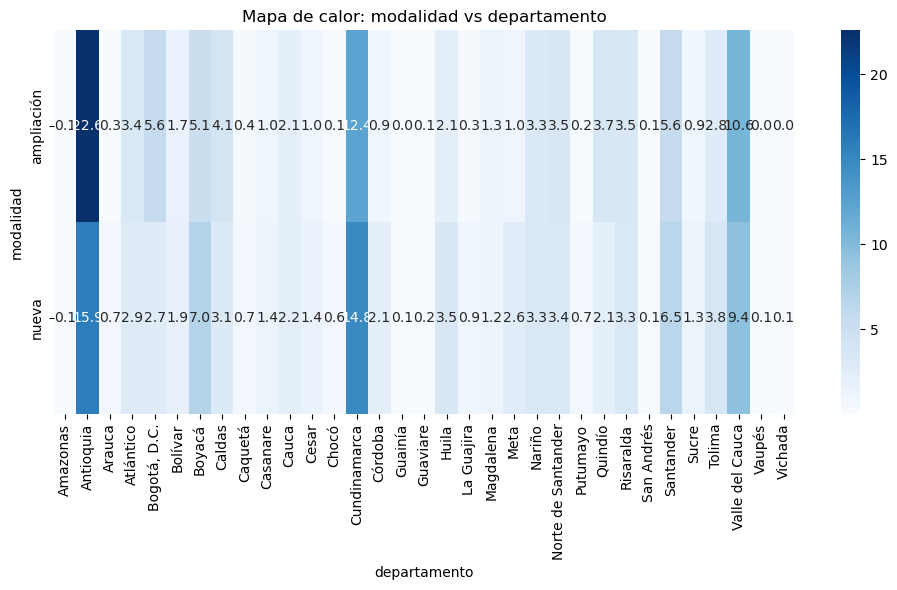


Tabla cruzada: destino vs tipo_vivi


tipo_vivi,No aplica,apartamentos,casas
destino,,,
administración pública,100.0,0.00,0.00
alojamiento,100.0,0.00,0.00
bodega,100.0,0.00,0.00
comercio,100.0,0.00,0.00
educación,100.0,0.00,0.00
industria,100.0,0.00,0.00
oficina,100.0,0.00,0.00
otros,100.0,0.00,0.00
religioso,100.0,0.00,0.00


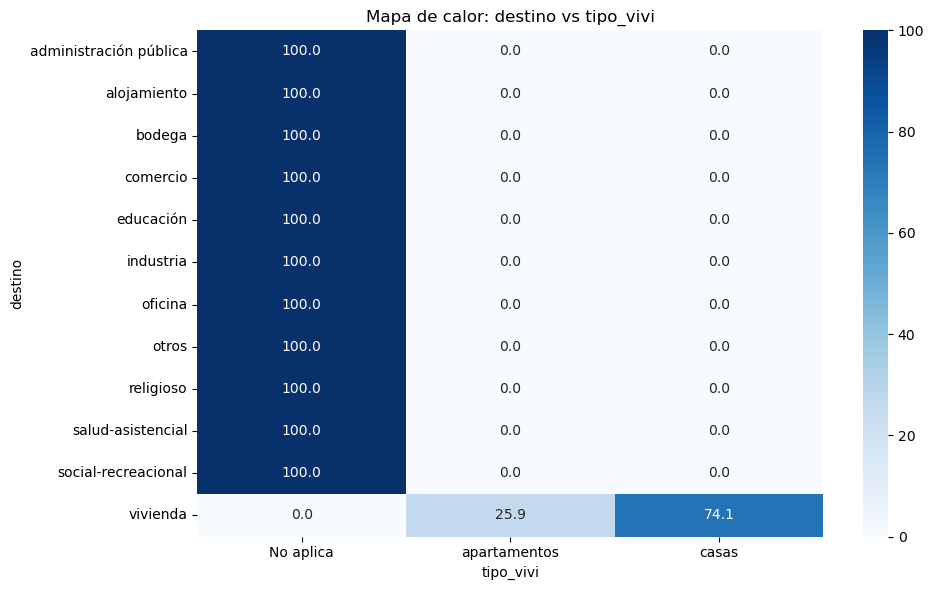


Tabla cruzada: destino vs vis_novis


vis_novis,No VIS,No aplica,VIP,VIS (no incluye VIP),"VIS (sin desagregación VIP, antes de 2013)"
destino,,,,,
administración pública,0.00,100.0,0.00,0.0,0.0
alojamiento,0.00,100.0,0.00,0.0,0.0
bodega,0.00,100.0,0.00,0.0,0.0
comercio,0.00,100.0,0.00,0.0,0.0
educación,0.00,100.0,0.00,0.0,0.0
industria,0.00,100.0,0.00,0.0,0.0
oficina,0.00,100.0,0.00,0.0,0.0
otros,0.00,100.0,0.00,0.0,0.0
religioso,0.00,100.0,0.00,0.0,0.0


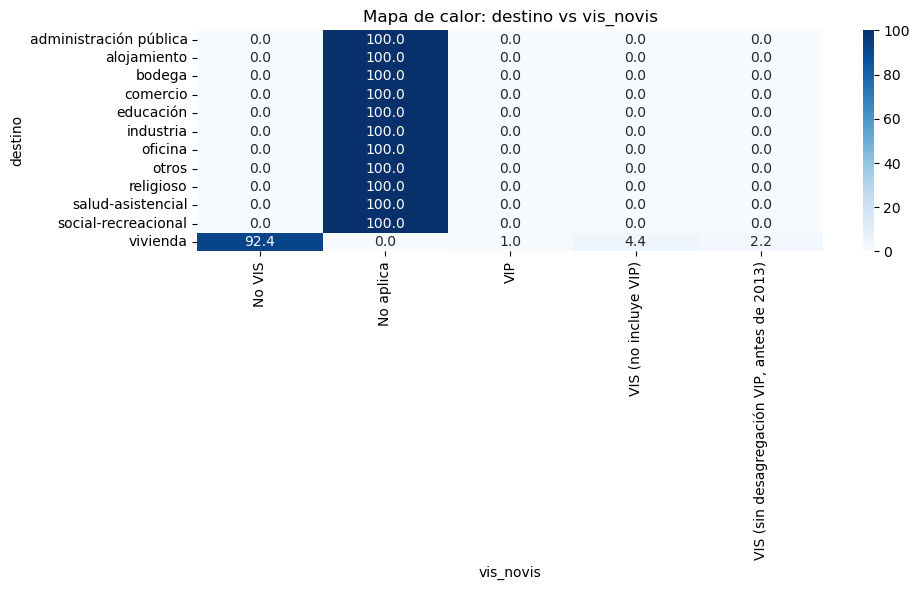


Tabla cruzada: destino vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
destino,,,,,,,
administración pública,0.00,0.00,0.00,0.00,0.00,0.00,100.0
alojamiento,0.00,0.00,0.00,0.00,0.00,0.00,100.0
bodega,0.00,0.00,0.00,0.00,0.00,0.00,100.0
comercio,0.00,0.00,0.00,0.00,0.00,0.00,100.0
educación,0.00,0.00,0.00,0.00,0.00,0.00,100.0
industria,0.00,0.00,0.00,0.00,0.00,0.00,100.0
oficina,0.00,0.00,0.00,0.00,0.00,0.00,100.0
otros,0.00,0.00,0.00,0.00,0.00,0.00,100.0
religioso,0.00,0.00,0.00,0.00,0.00,0.00,100.0


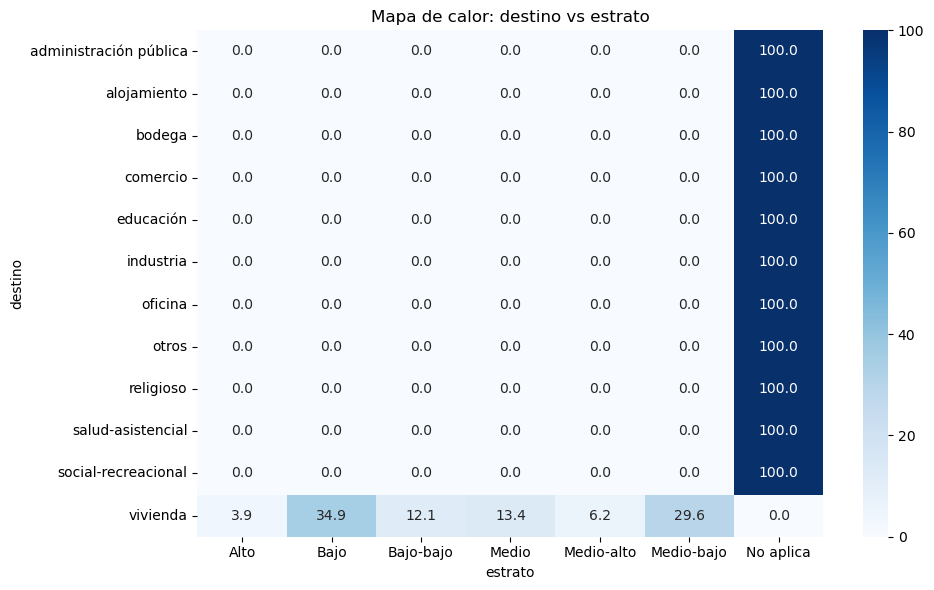


Tabla cruzada: destino vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
destino,,,,,,,,,,,,,,,,,,,,,
administración pública,0.36,15.81,1.14,1.78,11.47,2.35,4.06,1.71,1.78,2.42,...,1.21,1.64,1.85,0.36,5.56,1.92,2.42,5.41,0.36,0.57
alojamiento,0.20,15.73,0.70,2.09,6.00,4.63,6.00,1.82,0.57,1.34,...,0.77,2.49,2.84,0.75,6.42,2.51,3.53,7.47,0.17,0.15
bodega,0.15,19.48,0.54,6.32,2.29,4.36,5.63,3.12,0.85,1.11,...,0.54,2.48,4.81,0.07,4.48,0.99,2.69,10.26,0.22,0.04
comercio,0.16,17.80,0.92,3.41,2.08,2.43,6.71,3.01,0.56,1.69,...,0.93,2.24,2.97,0.17,6.78,1.53,3.04,7.61,0.13,0.14
educación,0.27,11.95,1.31,3.66,9.20,2.75,5.91,2.60,0.89,1.24,...,0.89,1.64,2.51,0.19,5.98,1.71,2.47,7.62,0.06,0.12
industria,0.10,23.55,0.45,3.80,10.47,2.01,4.37,2.88,0.30,0.79,...,0.45,0.92,2.04,0.00,6.83,0.50,1.27,7.59,0.05,0.02
oficina,0.15,16.40,0.94,3.87,16.48,3.80,5.04,2.40,0.58,1.34,...,0.35,2.86,2.28,0.15,6.00,0.89,1.67,8.15,0.15,0.08
otros,0.00,30.23,0.61,2.73,8.19,1.72,3.94,2.63,0.81,0.51,...,0.20,3.64,5.06,0.10,1.82,0.91,2.63,3.34,0.00,0.00
religioso,0.12,15.37,1.13,3.70,10.30,3.10,4.91,1.85,1.01,2.01,...,0.80,2.01,2.33,0.12,5.79,1.93,3.18,8.29,0.08,0.08


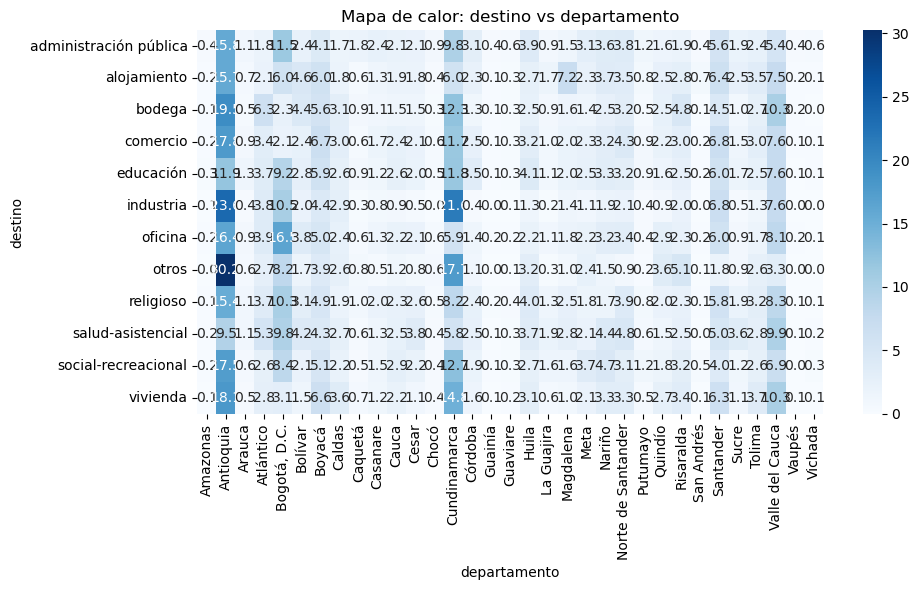


Tabla cruzada: tipo_vivi vs vis_novis


vis_novis,No VIS,No aplica,VIP,VIS (no incluye VIP),"VIS (sin desagregación VIP, antes de 2013)"
tipo_vivi,,,,,
No aplica,0.00,100.0,0.00,0.00,0.00
apartamentos,91.80,0.0,1.15,5.36,1.69
casas,92.63,0.0,0.93,4.06,2.38


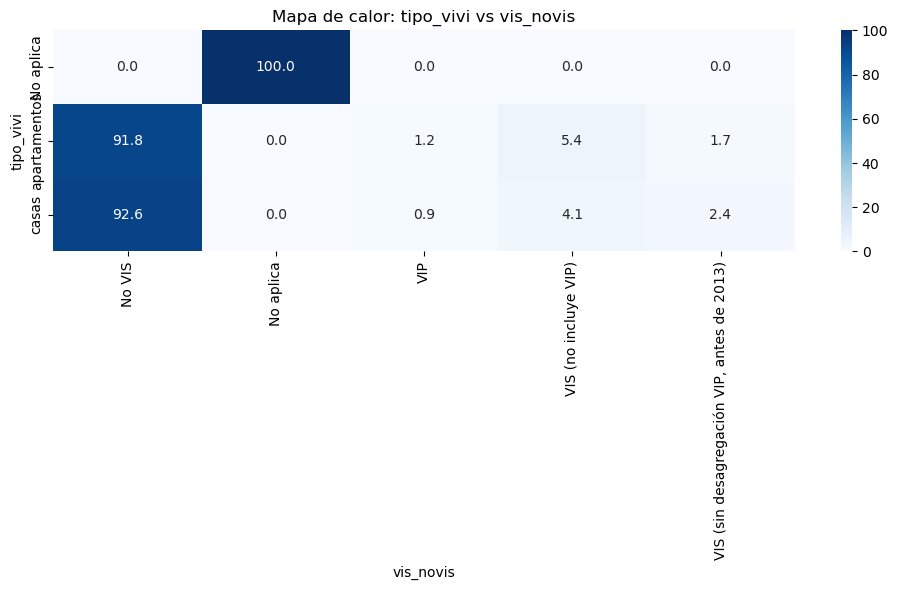


Tabla cruzada: tipo_vivi vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
tipo_vivi,,,,,,,
No aplica,0.00,0.00,0.00,0.00,0.00,0.00,100.0
apartamentos,3.55,31.27,8.06,15.35,6.11,35.67,0.0
casas,3.96,36.13,13.45,12.70,6.29,27.46,0.0


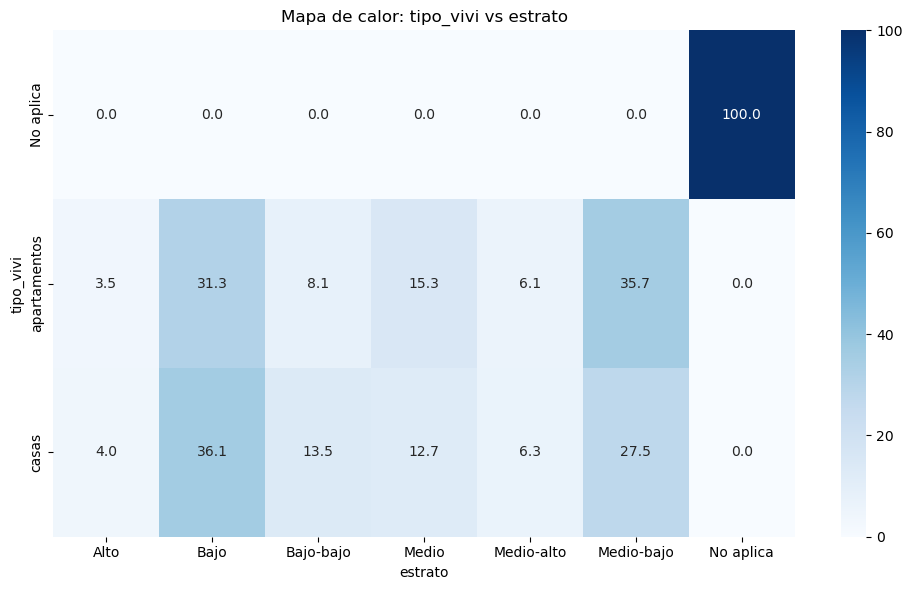


Tabla cruzada: tipo_vivi vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
tipo_vivi,,,,,,,,,,,,,,,,,,,,,
No aplica,0.17,17.21,0.89,3.69,5.39,2.89,5.95,2.75,0.64,1.49,...,0.82,2.12,2.97,0.20,6.10,1.55,2.77,7.87,0.12,0.13
apartamentos,0.05,24.92,0.26,3.92,6.26,1.91,6.62,3.46,0.31,0.93,...,0.52,2.16,2.85,0.09,8.25,1.38,2.61,10.49,0.05,0.02
casas,0.11,15.65,0.53,2.44,1.95,1.38,6.54,3.59,0.77,1.35,...,0.51,2.85,3.65,0.07,5.57,1.02,4.07,10.18,0.06,0.07


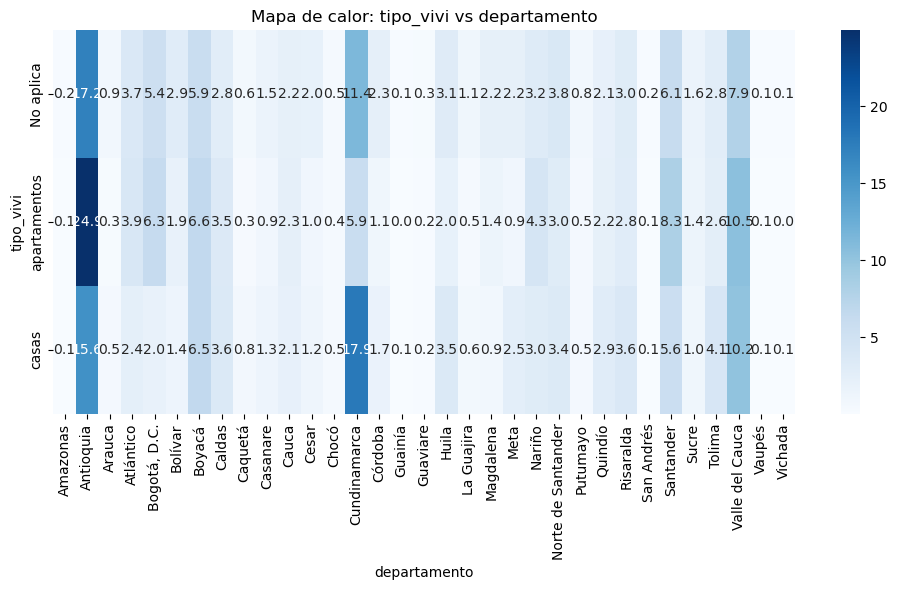


Tabla cruzada: vis_novis vs estrato


estrato,Alto,Bajo,Bajo-bajo,Medio,Medio-alto,Medio-bajo,No aplica
vis_novis,,,,,,,
No VIS,4.15,33.87,11.11,14.11,6.72,30.03,0.0
No aplica,0.00,0.00,0.00,0.00,0.00,0.00,100.0
VIP,0.22,46.46,38.36,2.25,0.34,12.37,0.0
VIS (no incluye VIP),0.23,47.01,20.60,5.44,0.62,26.11,0.0
"VIS (sin desagregación VIP, antes de 2013)",0.00,47.41,22.67,4.12,0.00,25.79,0.0


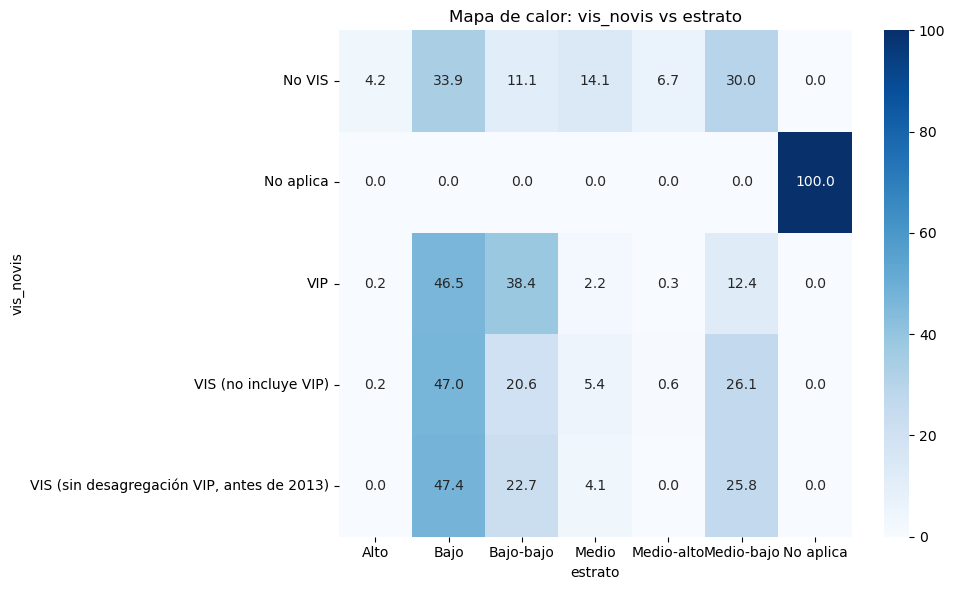


Tabla cruzada: vis_novis vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
vis_novis,,,,,,,,,,,,,,,,,,,,,
No VIS,0.10,18.73,0.41,2.67,2.56,1.45,6.77,3.55,0.64,1.24,...,0.52,2.65,3.36,0.09,6.42,1.09,3.32,10.32,0.06,0.06
No aplica,0.17,17.21,0.89,3.69,5.39,2.89,5.95,2.75,0.64,1.49,...,0.82,2.12,2.97,0.20,6.10,1.55,2.77,7.87,0.12,0.13
VIP,0.11,12.49,1.12,6.07,5.44,2.17,2.89,4.46,0.60,2.59,...,0.71,2.17,2.66,0.00,1.65,1.65,8.40,7.50,0.00,0.15
VIS (no incluye VIP),0.05,8.83,0.92,4.73,10.05,2.65,4.30,3.26,0.43,1.18,...,0.46,3.24,3.86,0.02,5.44,1.44,8.64,10.23,0.04,0.02
"VIS (sin desagregación VIP, antes de 2013)",0.00,10.41,1.47,3.99,9.18,1.61,4.02,4.19,1.46,0.70,...,0.00,2.75,6.13,0.00,3.69,1.39,7.19,8.83,0.00,0.00


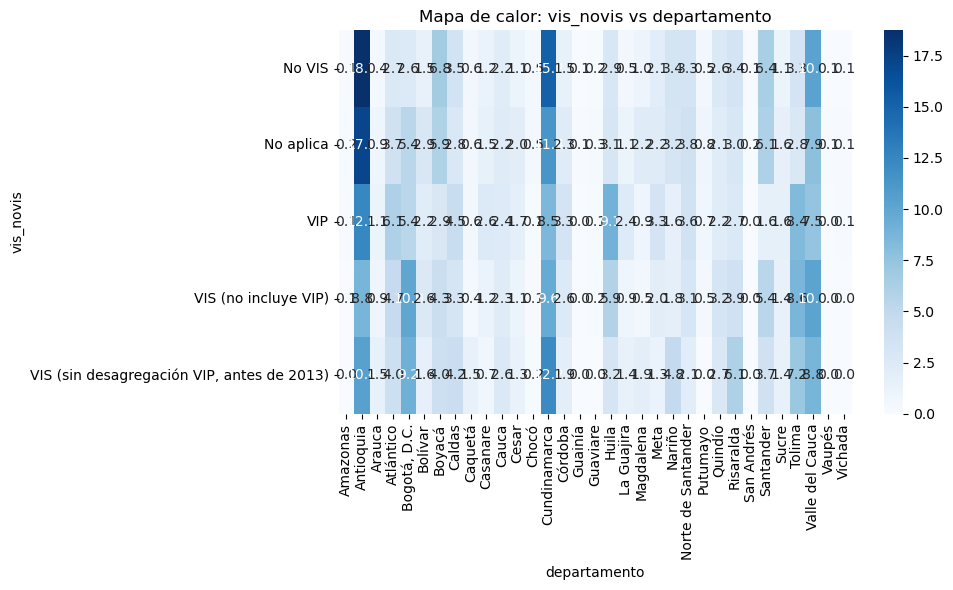


Tabla cruzada: estrato vs departamento


departamento,Amazonas,Antioquia,Arauca,Atlántico,"Bogotá, D.C.",Bolívar,Boyacá,Caldas,Caquetá,Casanare,...,Putumayo,Quindío,Risaralda,San Andrés,Santander,Sucre,Tolima,Valle del Cauca,Vaupés,Vichada
estrato,,,,,,,,,,,,,,,,,,,,,
Alto,0.00,19.23,0.00,4.49,8.33,3.62,0.56,7.67,0.31,0.06,...,0.01,3.58,7.59,0.00,6.95,1.04,2.47,9.81,0.00,0.00
Bajo,0.08,16.24,0.51,2.85,2.05,1.45,8.83,3.36,0.59,1.42,...,0.54,2.31,2.78,0.01,6.63,0.98,3.89,10.96,0.07,0.06
Bajo-bajo,0.06,11.49,1.41,3.88,3.78,1.90,6.51,2.14,1.38,2.69,...,2.07,1.98,2.92,0.01,3.96,1.68,2.74,8.90,0.05,0.18
Medio,0.09,21.04,0.14,2.61,3.86,1.25,4.33,3.62,0.74,0.94,...,0.09,2.92,3.82,0.30,6.85,1.35,3.51,11.03,0.02,0.03
Medio-alto,0.05,22.35,0.08,2.63,4.95,1.64,3.37,2.74,0.50,0.26,...,0.03,3.92,4.47,0.13,4.36,1.03,2.97,16.59,0.00,0.01
Medio-bajo,0.14,20.46,0.31,2.29,2.54,1.26,6.37,3.98,0.47,0.93,...,0.19,2.89,3.50,0.09,6.84,0.96,4.24,8.37,0.08,0.02
No aplica,0.17,17.21,0.89,3.69,5.39,2.89,5.95,2.75,0.64,1.49,...,0.82,2.12,2.97,0.20,6.10,1.55,2.77,7.87,0.12,0.13


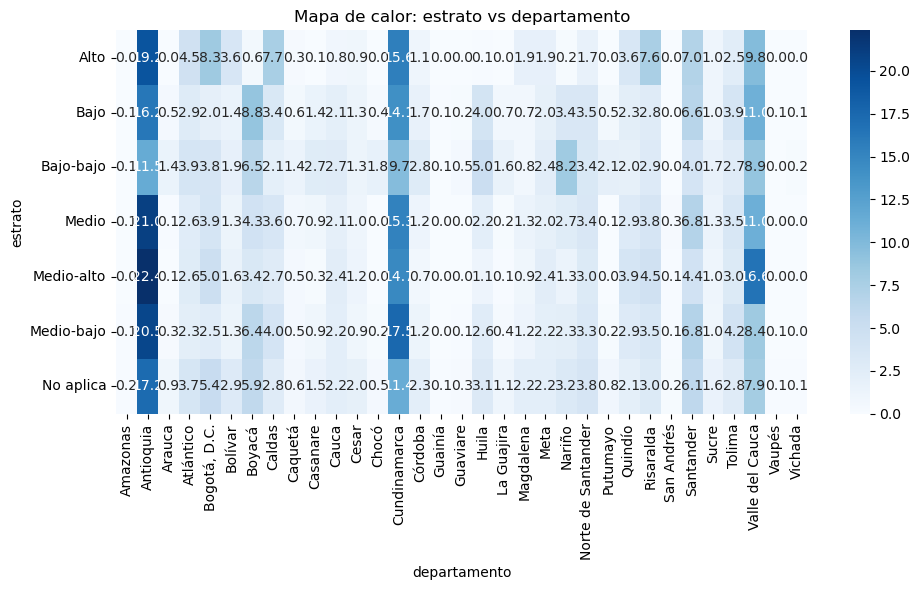

In [58]:
#Se eliminan estas dos variables dado que para el análisis cruzado municipios no es fácil de gráficas se reemplaza inicialmente con departamente y 
# cobertura no aporta información para análisis relevente

categoricas2 = categoricas.drop(columns=["municipio","cobertura","cobertura_municipio"])

# Cruzar todas las variables categóricas entre sí
for var1, var2 in combinations(categoricas2.columns, 2):

    print(f"\nTabla cruzada: {var1} vs {var2}")

    # Tabla cruzada en porcentajes por fila
    tabla = pd.crosstab(
        df[var1],
        df[var2],
        normalize="index",
        dropna=False
    ) * 100

    # Mostrar tabla
    display(tabla.round(2))

    # Mapa de calor
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        tabla,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )
    plt.title(f"Mapa de calor: {var1} vs {var2}")
    plt.xlabel(var2)
    plt.ylabel(var1)
    plt.tight_layout()
    plt.show()

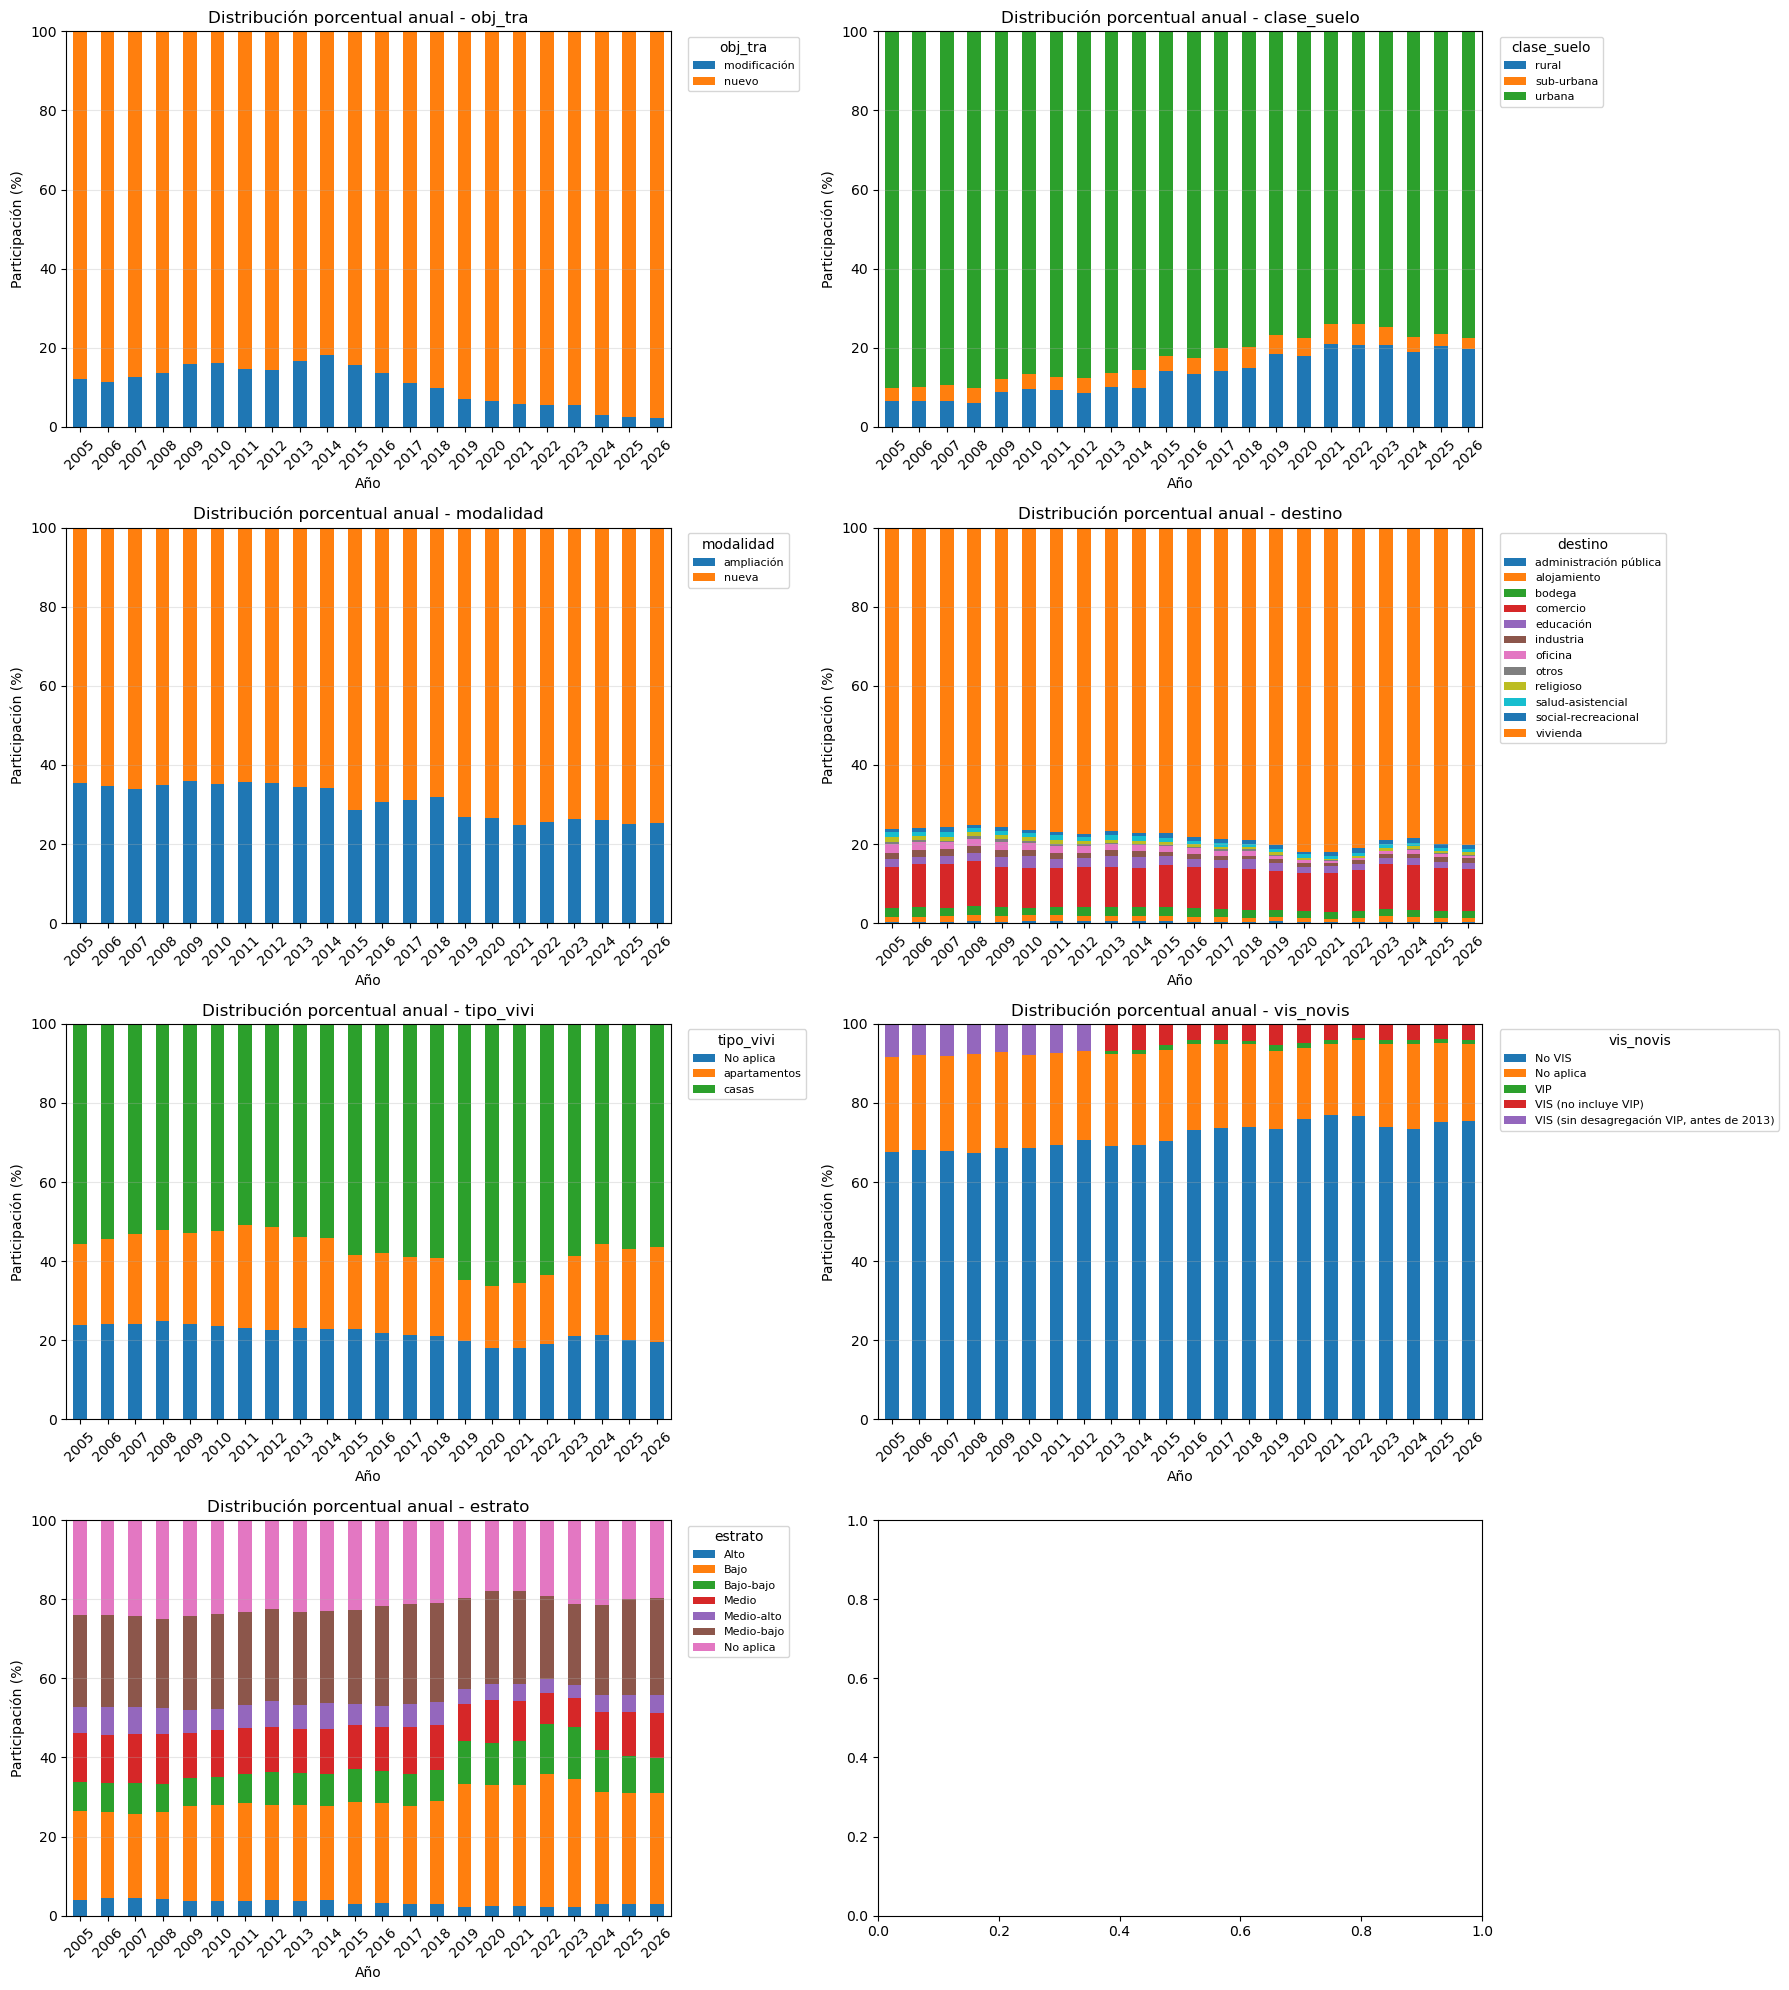

In [70]:
import matplotlib.pyplot as plt
import pandas as pd
import math

categoricas3 = ['obj_tra', 'clase_suelo', 'modalidad', 'destino','tipo_vivi', 'vis_novis', 'estrato', ]

columnas = 2
filas = math.ceil(len(categoricas3) / columnas)

fig, axes = plt.subplots(
    filas, columnas,
    figsize=(18, 5 * filas)
)

axes = axes.flatten()

for i, col in enumerate(categoricas3):

    # Tabla de frecuencias por año
    tabla = pd.crosstab(
        df["ano"],
        df[col],
        normalize="index"
    ) * 100

    # Gráfico apilado
    tabla.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        legend=False
    )

    axes[i].set_title(f"Distribución porcentual anual - {col}")
    axes[i].set_xlabel("Año")
    axes[i].set_ylabel("Participación (%)")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].set_ylim(0, 100)
    axes[i].grid(axis="y", alpha=0.3)

    # Leyenda individual
    axes[i].legend(
        title=col,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )

plt.tight_layout()
plt.show()

## 7. Relaciones entre variables numéricas

,area,unidades,licencias
area,1.000000,0.796869,0.194344
unidades,0.796869,1.000000,0.172300
licencias,0.194344,0.172300,1.000000


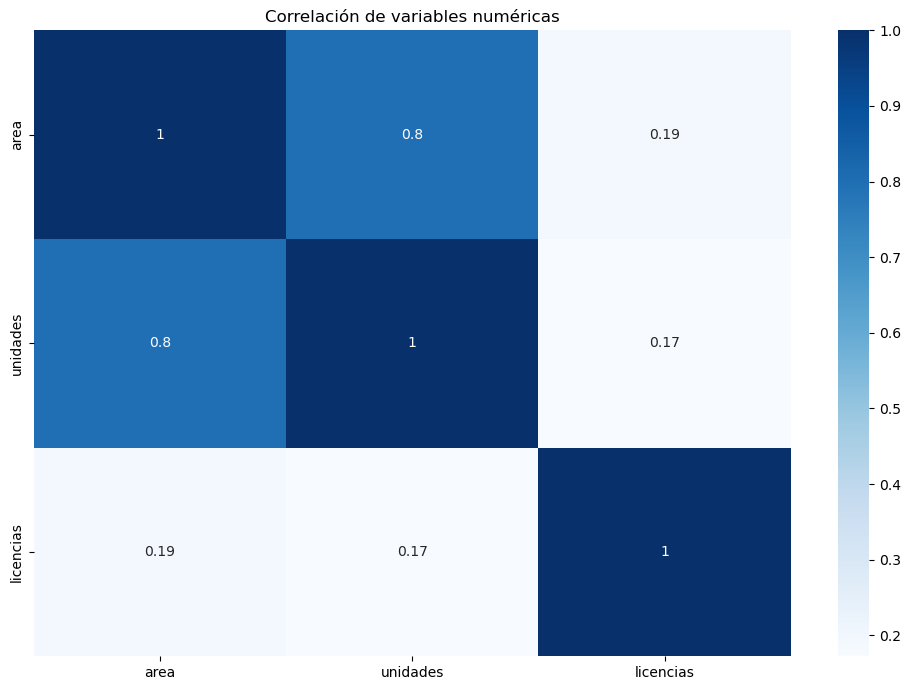

In [59]:
if numericas.shape[1] >= 2:
    correlaciones = numericas.corr()
    display(correlaciones)

    plt.figure(figsize=(10, 7))
    sns.heatmap(correlaciones, cmap="Blues", annot=True)
    plt.title("Correlación de variables numéricas")
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes variables numéricas para calcular correlaciones.")

### Gráfico de dispersión

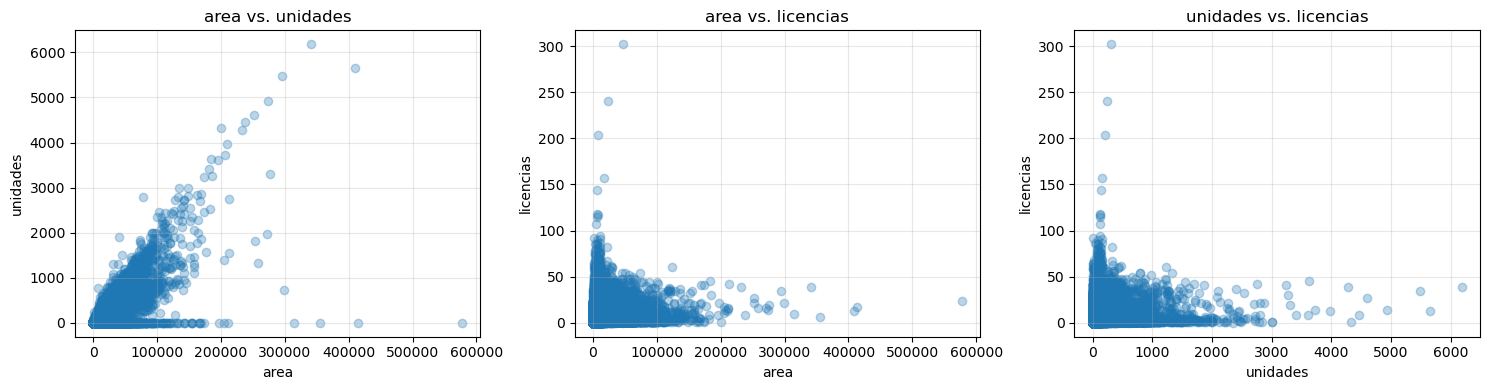

In [63]:
# Obtener todas las combinaciones de variables numéricas
pares = list(combinations(numericas.columns, 2))

if len(pares) > 0:

    columnas = 3
    filas = math.ceil(len(pares) / columnas)

    fig, axes = plt.subplots(
        filas, columnas,
        figsize=(15, 4 * filas)
    )

    axes = np.array(axes).flatten()

    for i, (variable_x, variable_y) in enumerate(pares):

        axes[i].scatter(
            df[variable_x],
            df[variable_y],
            alpha=0.3
        )

        axes[i].set_title(f"{variable_x} vs. {variable_y}")
        axes[i].set_xlabel(variable_x)
        axes[i].set_ylabel(variable_y)
        axes[i].grid(alpha=0.3)

    # Eliminar espacios sobrantes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

else:
    print("Se necesitan al menos dos variables numéricas.")

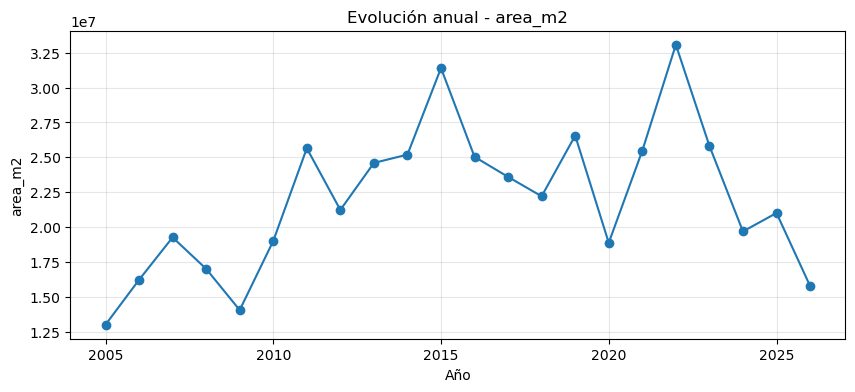

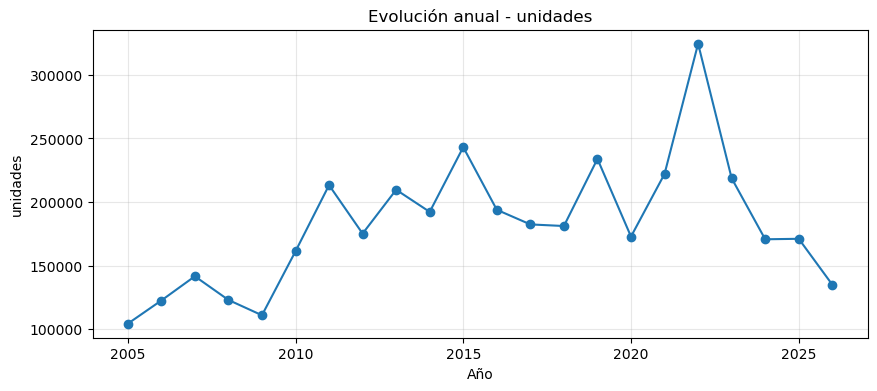

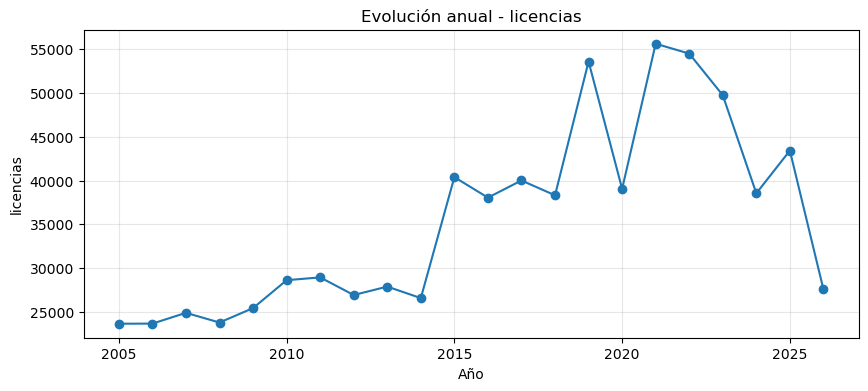

In [67]:
for col in ["area_m2", "unidades", "licencias"]:

    plt.figure(figsize=(10, 4))

    plt.plot(
        resumen_anual["ano"],
        resumen_anual[col],
        marker="o"
    )

    plt.title(f"Evolución anual - {col}")
    plt.xlabel("Año")
    plt.ylabel(col)
    plt.grid(alpha=0.3)

    plt.show()